# Bangla License Plate OCR — Conservative Instant Demo

Uses your already-trained model; no retraining is performed.

Shows clean images without bounding boxes for original, 10 px blur, and 20 px blur. It preserves detections from the original image and runs enhanced inference only as a fallback for missing fields. It does not merge competing enhanced labels over original detections.

Add the saved `final-training-v2` output and image dataset as Kaggle Inputs. Change `DEMO_FOLDER` in Cell 1 when using a new folder of images.


In [1]:
# CELL 1 — INSTALL + SETTINGS

import subprocess
import sys
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.3.*"],
    check=True
)

from pathlib import Path
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import yaml
import torch
from ultralytics import YOLO
from itertools import combinations


TRAINING_OUTPUT_ROOT = Path(
    "/kaggle/input/datasets/tanvirmahtabtaneem/best-path-and-yaml-file/BEST PATH AMD YAML FILE"
)
MODEL_PATH = (
    TRAINING_OUTPUT_ROOT
    / "best.pt"
)
DATA_YAML = TRAINING_OUTPUT_ROOT / "data.yaml"


DEMO_FOLDER = Path(
    "/kaggle/input/datasets/tanvirmahtabtaneem/sample/sample"
)

OUTPUT_FOLDER = Path("/kaggle/working/bangla_instant_demo")

IMG_SIZE = 960
CONF = 0.10
IOU = 0.50
BLUR_LEVELS = [0, 10, 20]
MAX_IMAGES = None  # Set to None to process every image in the folder.

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
DEVICE = 0 if torch.cuda.is_available() else "cpu"

OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Trained model not found: {MODEL_PATH}\n"
        "In Kaggle, add your saved final-training-v2 notebook output as an Input."
    )

if not DATA_YAML.is_file():
    raise FileNotFoundError(
        f"Class list/data.yaml not found: {DATA_YAML}\n"
        "Check that final-training-v2 is added as a Kaggle Input."
    )

if not DEMO_FOLDER.exists():
    raise FileNotFoundError(
        f"Image folder not found: {DEMO_FOLDER}\n"
        "Add the new images as a Kaggle Dataset Input, then change DEMO_FOLDER above."
    )

with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)
raw_names = data_config["names"]
if isinstance(raw_names, dict):
    class_names = [raw_names[k] for k in sorted(raw_names, key=lambda v: int(v))]
else:
    class_names = list(raw_names)

print("Model:", MODEL_PATH)
print("Image folder:", DEMO_FOLDER)
print("Classes:", len(class_names))
print("Device:", DEVICE)
print("Blur views:", BLUR_LEVELS, "px")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 30.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Model: /kaggle/input/datasets/tanvirmahtabtaneem/best-path-and-yaml-file/BEST PATH AMD YAML FILE/best.pt
Image folder: /kaggle/input/datasets/tanvirmahtabtaneem/sample/sample
Classes: 102
Device: 0
Blur views: [0, 10, 20] px


In [2]:
# CELL 2 — CONSERVATIVE OCR, SEQUENCE, AND MOTION BLUR
# Important: the original-image detections remain authoritative.
# Enhanced inference is used only to supplement missing characters;
# it never replaces a character already detected on the original image.

def apply_motion_blur(image, kernel_size):
    """Apply horizontal motion blur; 0 means the original image."""
    if kernel_size == 0:
        return image.copy()

    kernel = np.zeros((kernel_size, kernel_size), dtype=np.float32)
    kernel[kernel_size // 2, :] = 1.0 / kernel_size
    return cv2.filter2D(image, -1, kernel)


DIGIT_NAMES = {str(i) for i in range(10)}

# Normalize labels to avoid class-name casing/spacing issues.
SERIES_NAMES = {
    "a", "ba", "bha", "cha", "chha", "da", "dha", "e",
    "ga", "gha", "ha", "ja", "jha", "ka", "kha", "la",
    "ma", "na", "pa", "sa", "sha", "ta", "tha", "u"
}


def token_role(name):
    key = " ".join(str(name).strip().casefold().split())

    if key in DIGIT_NAMES:
        return "digit"
    if key == "metro":
        return "metro"
    if key in SERIES_NAMES:
        return "series"
    return "place"


def read_candidates(model, image, conf=CONF, imgsz=IMG_SIZE, augment=False):
    """Run one YOLO pass and retain normalized token boxes."""
    result = model.predict(
        source=image,
        imgsz=imgsz,
        conf=conf,
        iou=IOU,
        agnostic_nms=False,
        augment=augment,
        max_det=120,
        device=DEVICE,
        verbose=False
    )[0]

    height, width = image.shape[:2]
    candidates = []

    if result.boxes is None:
        return candidates

    for i in range(len(result.boxes)):
        class_id = int(result.boxes.cls[i].item())
        if not (0 <= class_id < len(class_names)):
            continue

        xywhn = result.boxes.xywhn[i].detach().cpu().numpy()
        xyxy = result.boxes.xyxy[i].detach().cpu().numpy()
        name = str(class_names[class_id]).strip()

        candidates.append({
            "class_id": class_id,
            "name": name,
            "role": token_role(name),
            "cx": float(xywhn[0]),
            "cy": float(xywhn[1]),
            "width": float(xywhn[2]),
            "height": float(xywhn[3]),
            "confidence": float(result.boxes.conf[i].item()),
            "box": [
                float(xyxy[0] / width),
                float(xyxy[1] / height),
                float(xyxy[2] / width),
                float(xyxy[3] / height)
            ]
        })

    return candidates


def same_physical_token(a, b):
    """True when two boxes likely refer to the same physical character/word."""
    ax1, ay1, ax2, ay2 = a["box"]
    bx1, by1, bx2, by2 = b["box"]

    inter_w = max(0.0, min(ax2, bx2) - max(ax1, bx1))
    inter_h = max(0.0, min(ay2, by2) - max(ay1, by1))
    intersection = inter_w * inter_h

    area_a = max(1e-9, (ax2 - ax1) * (ay2 - ay1))
    area_b = max(1e-9, (bx2 - bx1) * (by2 - by1))
    smaller_area = max(1e-9, min(area_a, area_b))

    center_close = (
        abs(a["cx"] - b["cx"]) <= max(0.012, 0.28 * min(a["width"], b["width"]))
        and abs(a["cy"] - b["cy"]) <= max(0.018, 0.40 * min(a["height"], b["height"]))
    )

    return center_close and (intersection / smaller_area >= 0.35)


def deduplicate_candidates(candidates):
    """
    Remove overlapping alternative labels for the same box.
    This function is only applied within one inference pass.
    """
    kept = []

    for candidate in sorted(candidates, key=lambda t: t["confidence"], reverse=True):
        if not any(same_physical_token(candidate, old) for old in kept):
            kept.append(candidate)

    return kept


def enhance_for_fallback(image):
    """Mild local contrast enhancement. Never used to overwrite original detections."""
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=1.8, tileGridSize=(8, 8))
    l_channel = clahe.apply(l_channel)
    return cv2.cvtColor(
        cv2.merge((l_channel, a_channel, b_channel)),
        cv2.COLOR_LAB2BGR
    )


def choose_six_digits(digit_tokens):
    """
    Keep digits in left-to-right order.
    If there are more than six, choose the six with the best confidence
    and spatial spacing balance. No character is invented.
    """
    digits = sorted(digit_tokens, key=lambda t: t["cx"])

    if len(digits) <= 6:
        return digits

    if len(digits) > 12:
        digits = sorted(
            sorted(digits, key=lambda t: t["confidence"], reverse=True)[:12],
            key=lambda t: t["cx"]
        )

    best = None
    best_score = -1e9

    for combo in combinations(digits, 6):
        xs = np.array([t["cx"] for t in combo], dtype=np.float32)
        gaps = np.diff(xs)

        if len(gaps) == 0 or float(np.mean(gaps)) <= 0:
            continue

        mean_gap = float(np.mean(gaps))
        spacing_cv = float(np.std(gaps) / max(mean_gap, 1e-6))
        mean_conf = float(np.mean([t["confidence"] for t in combo]))
        coverage = float(xs[-1] - xs[0])

        # Confidence is the main signal; spacing is only a modest tie-breaker.
        score = mean_conf + 0.05 * coverage - 0.08 * spacing_cv

        if score > best_score:
            best_score = score
            best = combo

    return list(best) if best is not None else digits[:6]


def decode_plate(candidates):
    """Decode one location, Metro if present, one series label, then digits."""
    tokens = deduplicate_candidates(candidates)

    places = [t for t in tokens if t["role"] == "place"]
    metros = [t for t in tokens if t["role"] == "metro"]
    series = [t for t in tokens if t["role"] == "series"]
    digits = [t for t in tokens if t["role"] == "digit"]

    # There should be at most one city/location label.
    place = None
    if places:
        if metros:
            metro_x = max(metros, key=lambda t: t["confidence"])["cx"]
            before_metro = [t for t in places if t["cx"] < metro_x]
            place_pool = before_metro if before_metro else places
        else:
            place_pool = places
        place = max(place_pool, key=lambda t: t["confidence"])

    # Keep the strongest Metro detection if present.
    metro = max(metros, key=lambda t: t["confidence"]) if metros else None

    # The series label is the first series-class candidate before the first digit.
    # Do not remove it using a vertical-row filter; that was the regression.
    series_token = None
    if series:
        first_digit_x = min((t["cx"] for t in digits), default=1.0)
        series_pool = [t for t in series if t["cx"] < first_digit_x + 0.06]
        if not series_pool:
            series_pool = series
        series_token = min(
            series_pool,
            key=lambda t: (t["cx"], -t["confidence"])
        )

    chosen_digits = choose_six_digits(digits)

    output = []
    if place is not None:
        output.append(place)
    if metro is not None:
        output.append(metro)
    if series_token is not None:
        output.append(series_token)
    output.extend(chosen_digits)

    return output


def supplement_missing_tokens(model, image, base_candidates):
    """
    Fallback pass only:
      - original detections are preserved;
      - enhanced detections overlapping original boxes are ignored;
      - only missing structural roles / missing digits may be supplemented.
    """
    base = deduplicate_candidates(base_candidates)
    selected_base = decode_plate(base)

    base_roles = {t["role"] for t in selected_base}
    base_digit_count = sum(t["role"] == "digit" for t in selected_base)

    missing_role = (
        "place" if "place" not in base_roles else
        "metro" if "metro" not in base_roles else
        "series" if "series" not in base_roles else
        None
    )
    need_digits = base_digit_count < 6

    if missing_role is None and not need_digits:
        return base

    enhanced = enhance_for_fallback(image)
    fallback = read_candidates(
        model,
        enhanced,
        conf=0.045,
        imgsz=1280,
        augment=True
    )
    fallback = deduplicate_candidates(fallback)

    additions = []
    current = list(base)

    for candidate in sorted(fallback, key=lambda t: t["confidence"], reverse=True):
        role = candidate["role"]

        # Never replace/conflict with a token already detected on the original image.
        if any(same_physical_token(candidate, original) for original in base):
            continue
        if any(same_physical_token(candidate, added) for added in additions):
            continue

        allowed = False

        if missing_role is not None and role == missing_role:
            allowed = True

        if need_digits and role == "digit":
            # Supplement only around the lower/numeric row if its location is known.
            existing_digits = [t for t in current + additions if t["role"] == "digit"]
            if existing_digits:
                median_y = float(np.median([t["cy"] for t in existing_digits]))
                if abs(candidate["cy"] - median_y) <= 0.16:
                    allowed = True
            else:
                allowed = True

        if allowed:
            additions.append(candidate)
            current.append(candidate)

        current_decoded = decode_plate(current)
        if (
            sum(t["role"] == "digit" for t in current_decoded) >= 6
            and "series" in {t["role"] for t in current_decoded}
            and "place" in {t["role"] for t in current_decoded}
        ):
            break

    return deduplicate_candidates(base + additions)


def predict_image(model, image):
    """Original pass first; only supplement if a structural item or digit is missing."""
    base = read_candidates(
        model,
        image,
        conf=CONF,
        imgsz=IMG_SIZE,
        augment=False
    )
    base = deduplicate_candidates(base)
    decoded = decode_plate(base)

    digits = sum(t["role"] == "digit" for t in decoded)
    roles = {t["role"] for t in decoded}

    needs_fallback = (
        digits < 6
        or "series" not in roles
        or "place" not in roles
    )

    candidates = supplement_missing_tokens(model, image, base) if needs_fallback else base
    return decode_plate(candidates)


def draw_selected_tokens(image, tokens):
    """Draw only decoded tokens, not every raw false-positive candidate."""
    output = image.copy()
    height, width = output.shape[:2]

    for token in tokens:
        x1n, y1n, x2n, y2n = token["box"]
        x1 = max(0, min(width - 1, int(x1n * width)))
        y1 = max(0, min(height - 1, int(y1n * height)))
        x2 = max(0, min(width - 1, int(x2n * width)))
        y2 = max(0, min(height - 1, int(y2n * height)))

        cv2.rectangle(output, (x1, y1), (x2, y2), (40, 220, 40), 2)
        label = f"{token['name']} {token['confidence']:.2f}"
        cv2.putText(
            output, label, (x1, max(12, y1 - 4)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.38, (0, 0, 0), 2, cv2.LINE_AA
        )
        cv2.putText(
            output, label, (x1, max(12, y1 - 4)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.38, (40, 220, 40), 1, cv2.LINE_AA
        )

    return output


print("Conservative OCR and blur functions are ready.")


Conservative OCR and blur functions are ready.


Final model loaded. Starting conservative instant demo...

Class ID: 11 | Class name: A
Class ID: 26 | Class name: Ma
Class ID: 27 | Class name: Na
Class ID: 31 | Class name: Ta
Images selected: 31
Each image will show original, blur 10 px, and blur 20 px.

Original-image detections are preserved. Enhanced inference only supplements missing tokens.

IMAGE 1/31: p_0694df64fbcd4a3eb53681493a83d65d.jpg
Blur  0 px: Dhaka Metro Ga 1 6 4 1 0 9 | digits=6/6 | avg_conf=0.888
Blur 10 px: Dhaka Metro Ga 1 6 4 1 0 9 | digits=6/6 | avg_conf=0.862
Blur 20 px: Dhaka Metro Ga 1 6 4 1 0 9 | digits=6/6 | avg_conf=0.462


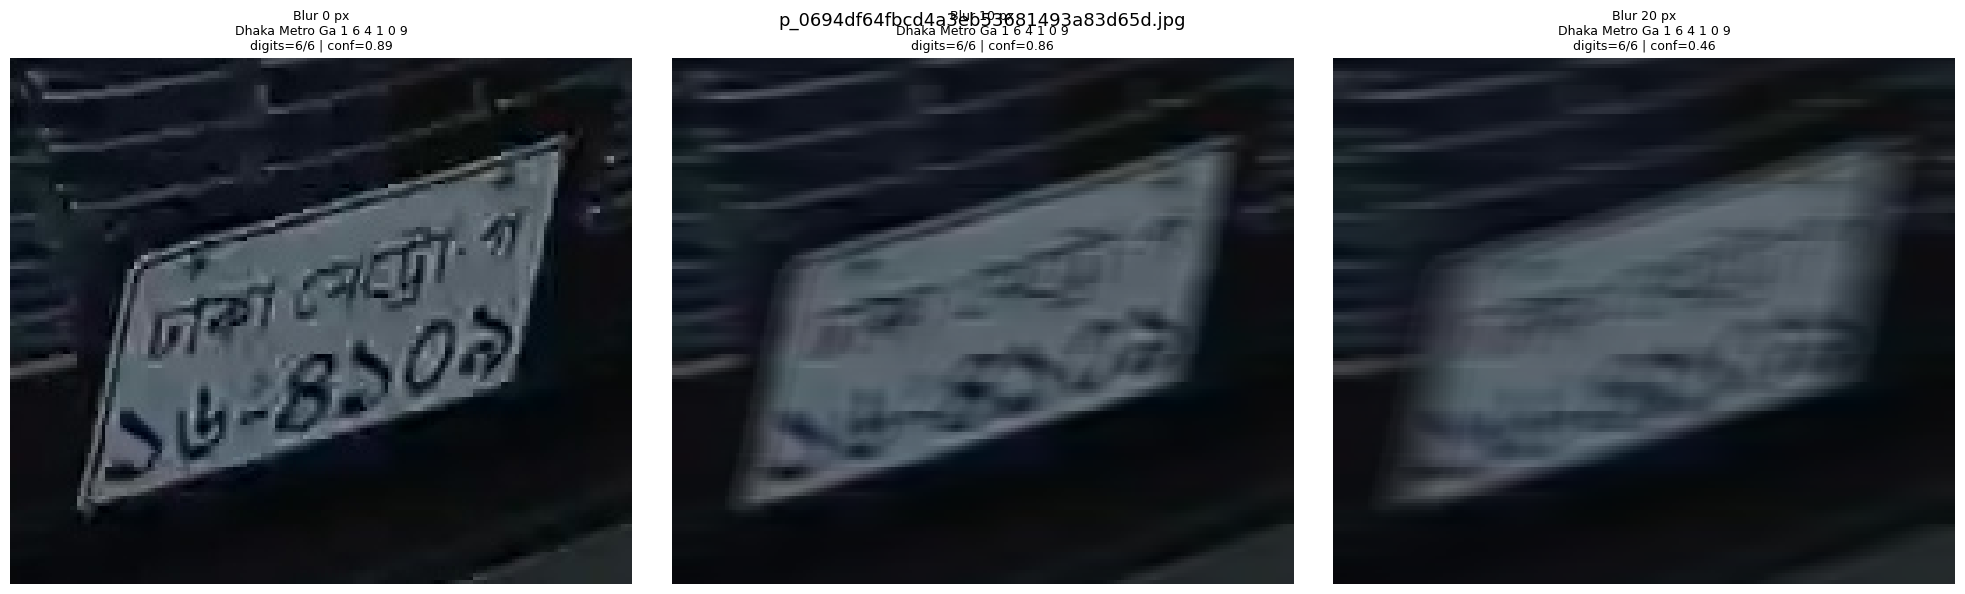

Saved comparison: /kaggle/working/bangla_instant_demo/p_0694df64fbcd4a3eb53681493a83d65d_comparison.png
IMAGE 2/31: p_090d34ae18a74750ab8844b6d6d89c7f.jpg
Blur  0 px: Dhaka Metro La 6 6 5 4 3 4 | digits=6/6 | avg_conf=0.782
Blur 10 px: Dhaka Metro Ha 1 8 5 4 6 9 | digits=6/6 | avg_conf=0.425
Blur 20 px: Dhaka Metro Ha 2 7 7 5 7 8 | digits=6/6 | avg_conf=0.191
  CHECK: low confidence


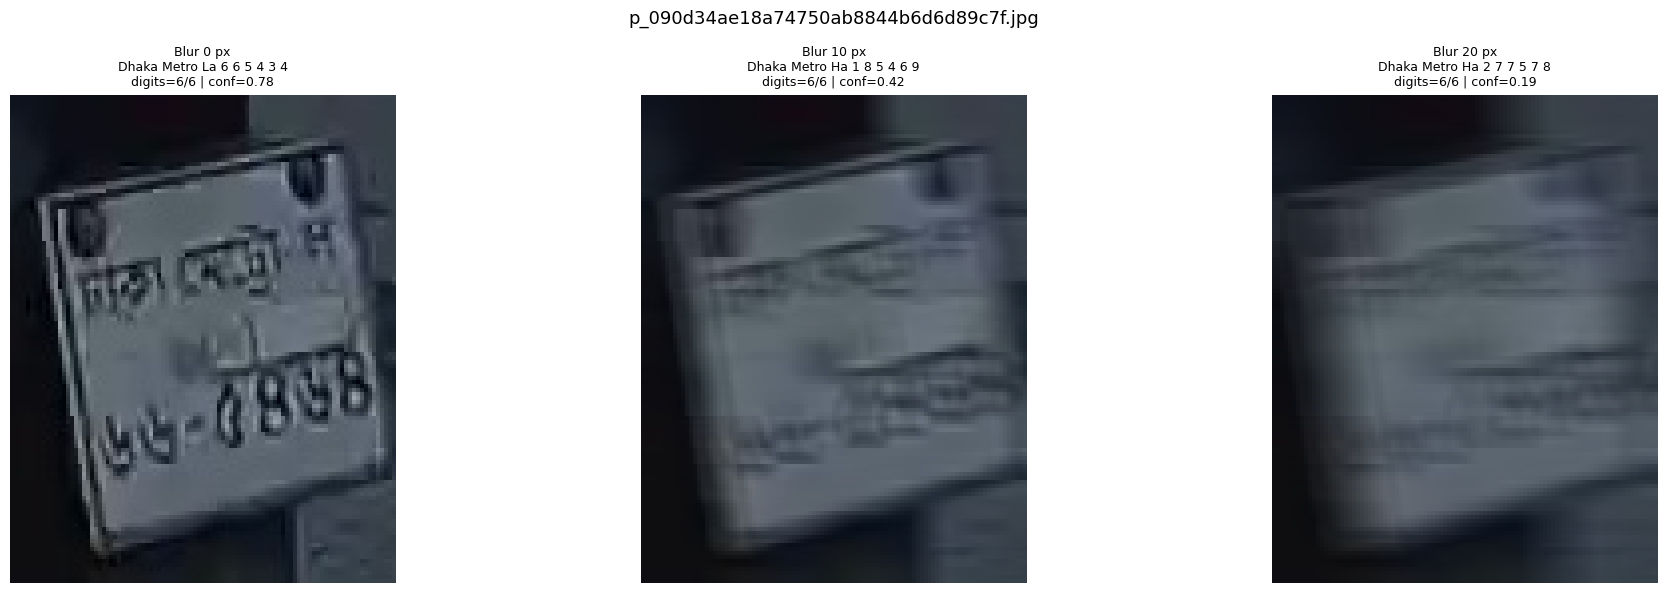

Saved comparison: /kaggle/working/bangla_instant_demo/p_090d34ae18a74750ab8844b6d6d89c7f_comparison.png
IMAGE 3/31: p_109a9dff6ff14637aa32ae627ec7fb3f.jpg
Blur  0 px: Dhaka Metro Ka 1 9 3 9 5 6 | digits=6/6 | avg_conf=0.841
Blur 10 px: Dhaka Metro U 8 1 1 9 5 6 | digits=6/6 | avg_conf=0.586
Blur 20 px: Dhaka Metro 2 9 4 7 7 4 | digits=6/6 | avg_conf=0.420
  CHECK: series label missing


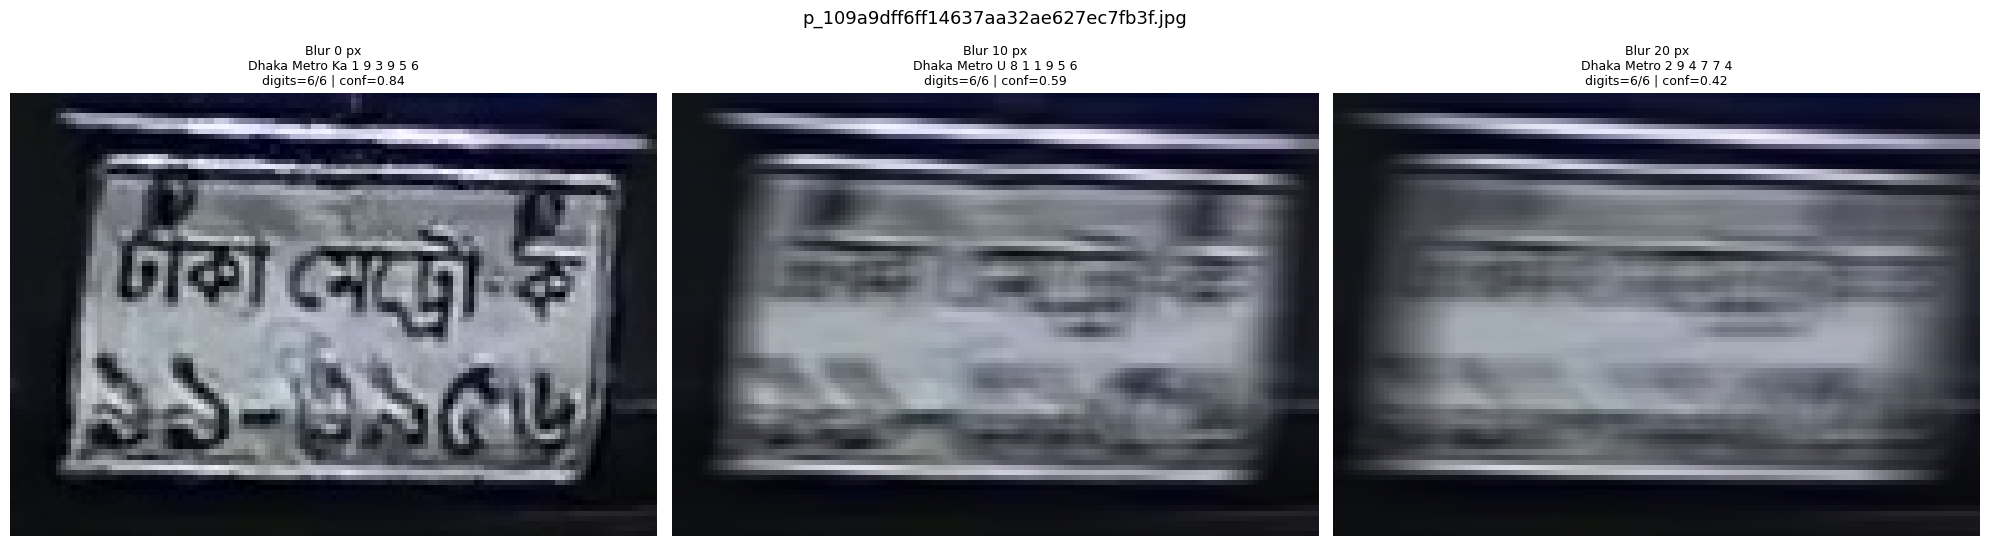

Saved comparison: /kaggle/working/bangla_instant_demo/p_109a9dff6ff14637aa32ae627ec7fb3f_comparison.png
IMAGE 4/31: p_1b0efa3aa94c48009df9b930c45fe74c.jpg
Blur  0 px: Dhaka Metro A 1 1 5 8 3 2 | digits=6/6 | avg_conf=0.879
Blur 10 px: Dhaka Metro Ha 1 1 5 8 3 2 | digits=6/6 | avg_conf=0.787
Blur 20 px: Dhaka Metro Ha 1 1 5 5 5 2 | digits=6/6 | avg_conf=0.327
  CHECK: low confidence


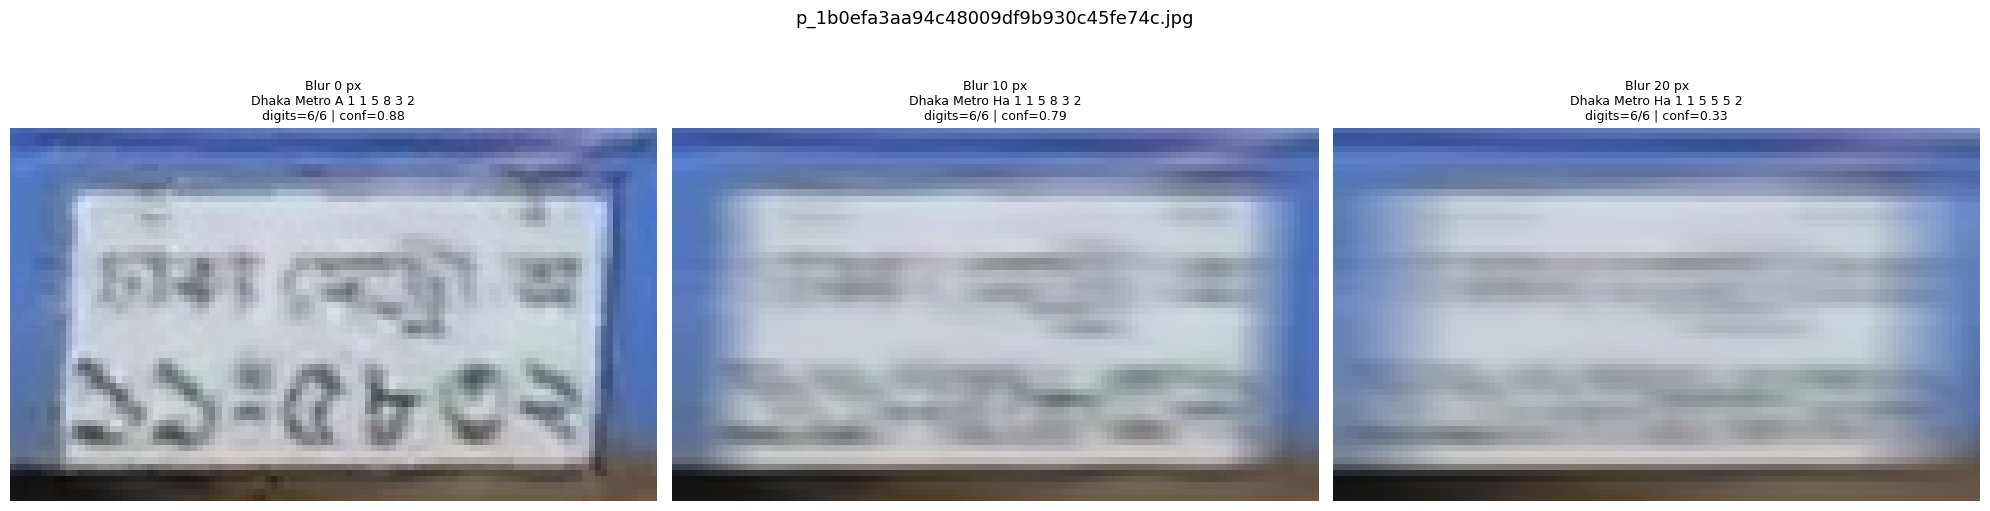

Saved comparison: /kaggle/working/bangla_instant_demo/p_1b0efa3aa94c48009df9b930c45fe74c_comparison.png
IMAGE 5/31: p_1d412b8f5cb24a8b99fb1e820ab15fee.jpg
Blur  0 px: Dhaka Metro Ga 4 7 7 9 7 0 | digits=6/6 | avg_conf=0.844
Blur 10 px: Dhaka Metro Ga 4 7 7 1 7 0 | digits=6/6 | avg_conf=0.763
Blur 20 px: Dhaka Metro Ga 4 7 7 2 7 1 | digits=6/6 | avg_conf=0.399


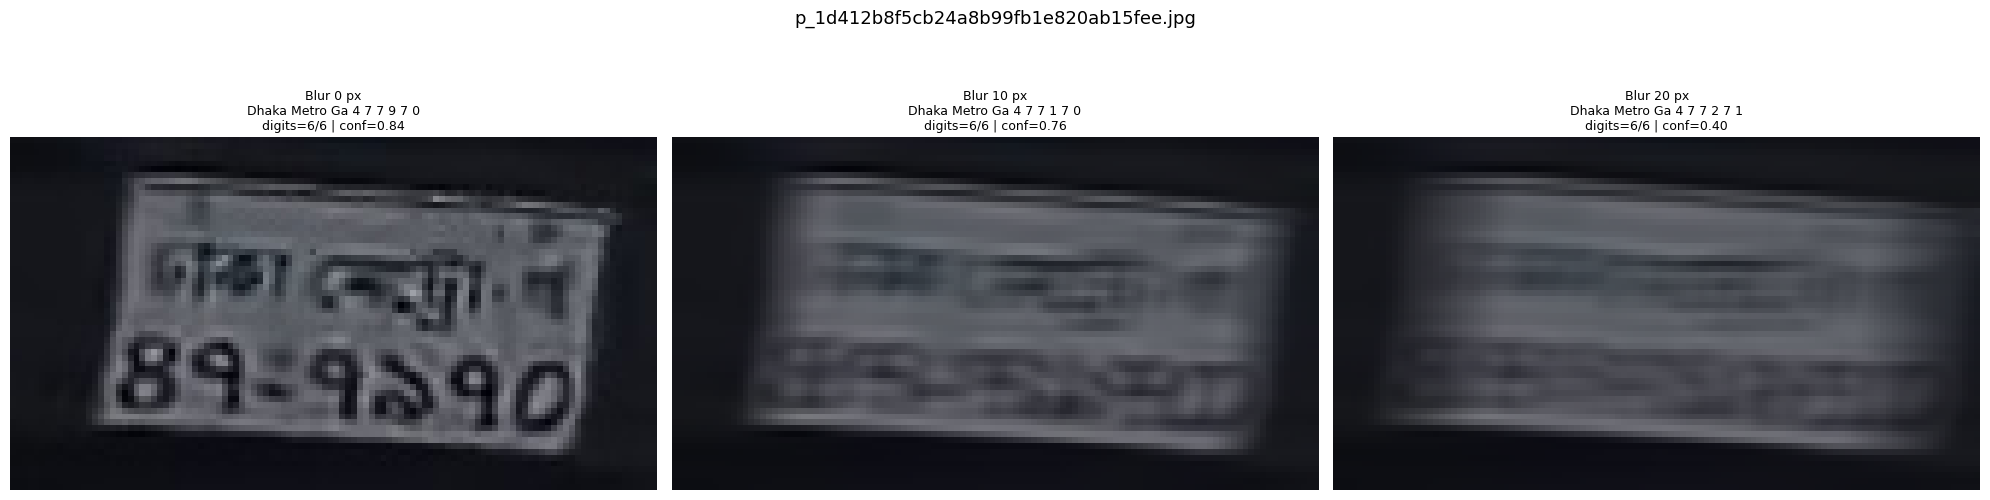

Saved comparison: /kaggle/working/bangla_instant_demo/p_1d412b8f5cb24a8b99fb1e820ab15fee_comparison.png
IMAGE 6/31: p_1e2ab3f7ca744d5eb983fbda4b7ada69.jpg
Blur  0 px: Dhaka Metro THA 1 3 7 0 8 0 | digits=6/6 | avg_conf=0.853
Blur 10 px: Dhaka Metro THA 1 3 3 0 8 7 | digits=6/6 | avg_conf=0.405
Blur 20 px: Dhaka Metro 7 7 6 7 2 8 | digits=6/6 | avg_conf=0.174
  CHECK: series label missing, low confidence


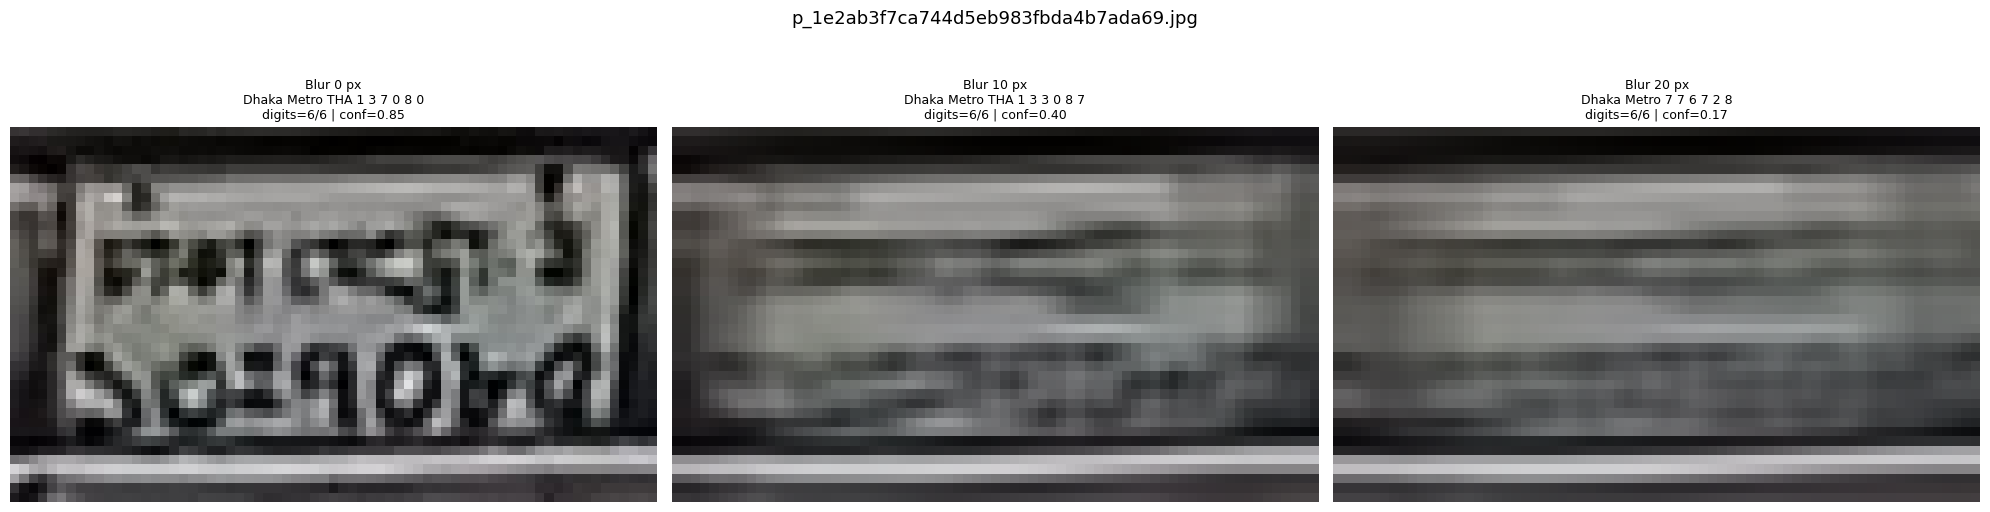

Saved comparison: /kaggle/working/bangla_instant_demo/p_1e2ab3f7ca744d5eb983fbda4b7ada69_comparison.png
IMAGE 7/31: p_21996f01815845a99cd33091becce2b0.jpg
Blur  0 px: Metro 1 1 0 0 1 8 | digits=6/6 | avg_conf=0.864
  CHECK: location missing, series label missing
Blur 10 px: Metro 1 1 5 7 1 8 | digits=6/6 | avg_conf=0.489
  CHECK: location missing, series label missing
Blur 20 px: Chatto Metro 1 1 4 5 2 5 | digits=6/6 | avg_conf=0.313
  CHECK: series label missing, low confidence


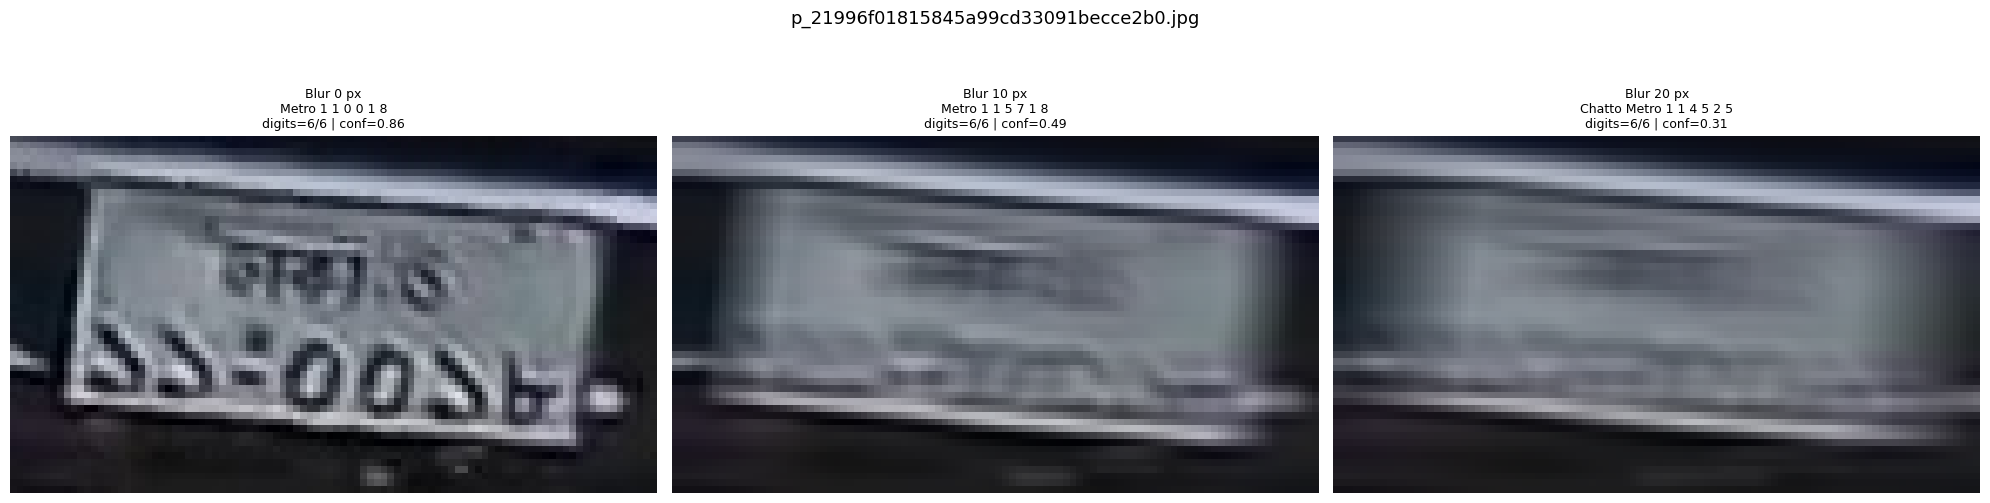

Saved comparison: /kaggle/working/bangla_instant_demo/p_21996f01815845a99cd33091becce2b0_comparison.png
IMAGE 8/31: p_26f87c7e4a364ddbbae59c20fad5c3ac.jpg
Blur  0 px: Dhaka Metro Cha 5 2 1 3 2 1 | digits=6/6 | avg_conf=0.836
Blur 10 px: Dhaka Metro Cha 5 9 1 3 2 1 | digits=6/6 | avg_conf=0.501
Blur 20 px: Dhaka Metro 9 7 7 1 2 7 | digits=6/6 | avg_conf=0.344
  CHECK: series label missing, low confidence


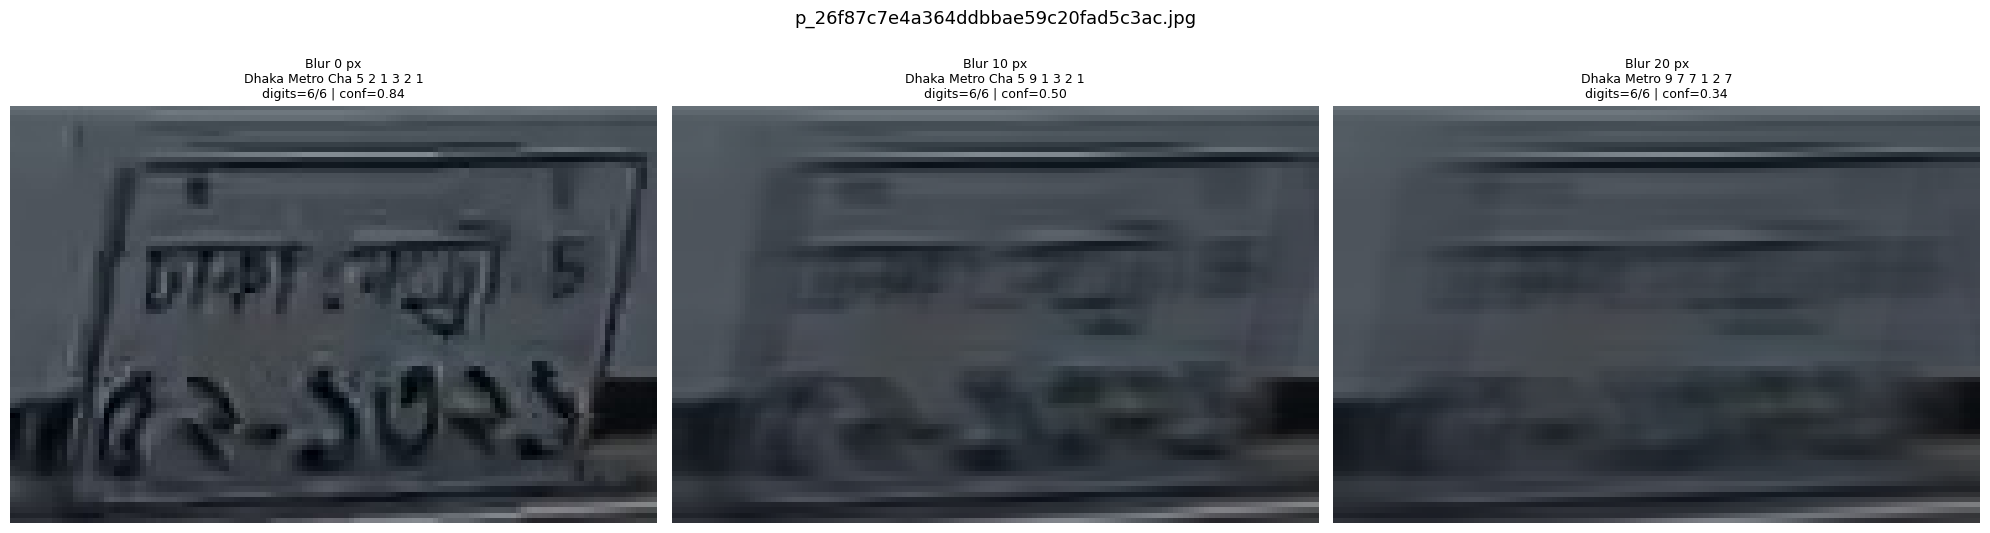

Saved comparison: /kaggle/working/bangla_instant_demo/p_26f87c7e4a364ddbbae59c20fad5c3ac_comparison.png
IMAGE 9/31: p_314b3644a5684a7394a20e58006f206d.jpg
Blur  0 px: Manikganj Jha 1 1 0 0 0 3 | digits=6/6 | avg_conf=0.908
  CHECK: Metro missing
Blur 10 px: Manikganj 1 1 0 0 0 3 | digits=6/6 | avg_conf=0.747
  CHECK: Metro missing, series label missing
Blur 20 px: Dhaka 1 1 7 1 1 3 | digits=6/6 | avg_conf=0.352
  CHECK: Metro missing, series label missing


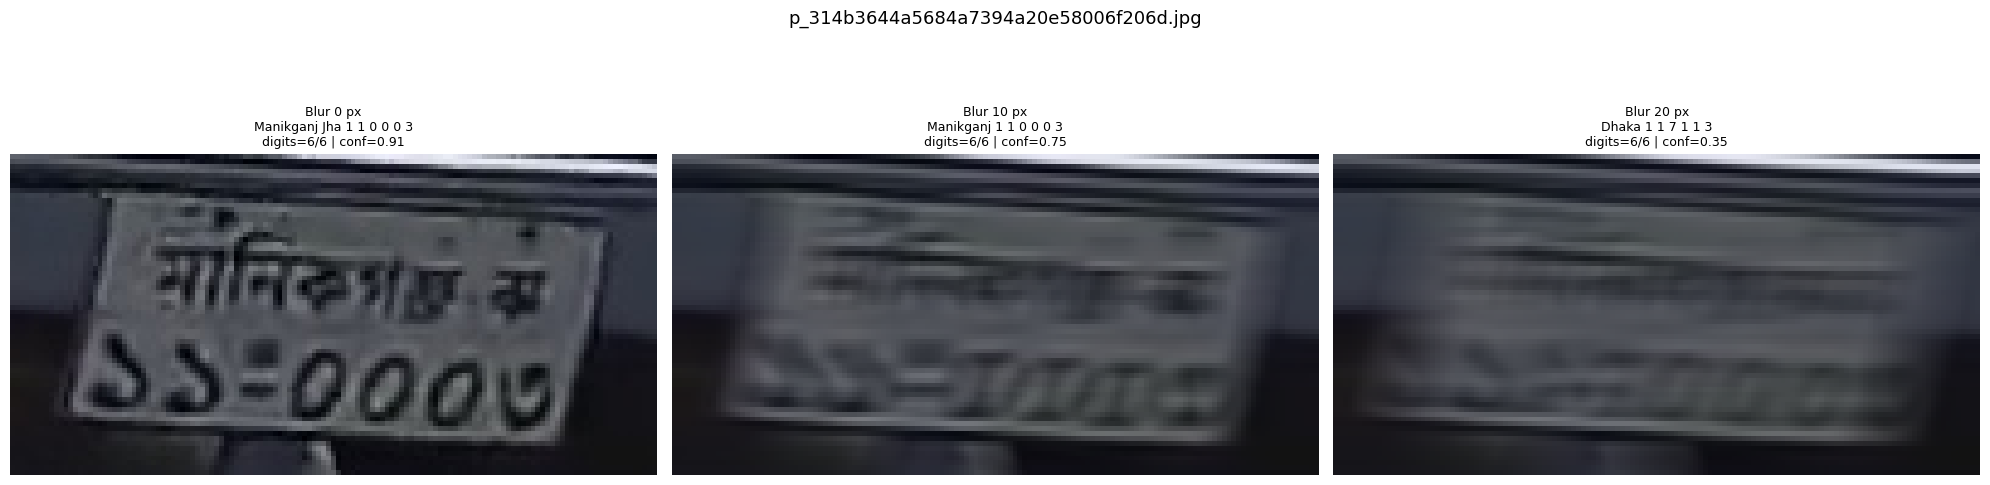

Saved comparison: /kaggle/working/bangla_instant_demo/p_314b3644a5684a7394a20e58006f206d_comparison.png
IMAGE 10/31: p_40ce9cefca284ce0b73c314a3f198dbf.jpg
Blur  0 px: Dhaka Metro Ga 3 9 2 4 9 1 | digits=6/6 | avg_conf=0.870
Blur 10 px: Dhaka Metro Ga 3 1 2 4 9 1 | digits=6/6 | avg_conf=0.765
Blur 20 px: Dhaka Metro Cha 5 1 4 4 4 5 | digits=6/6 | avg_conf=0.368


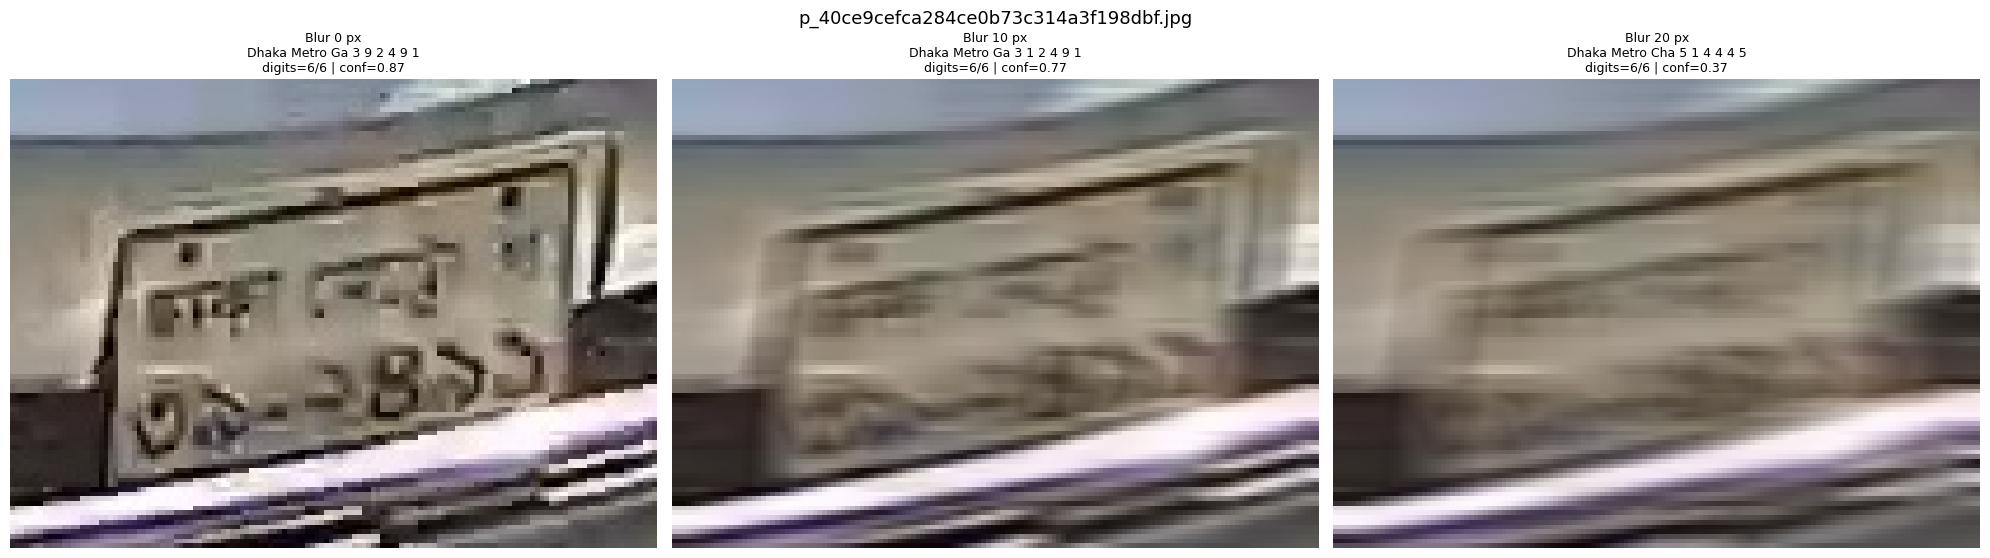

Saved comparison: /kaggle/working/bangla_instant_demo/p_40ce9cefca284ce0b73c314a3f198dbf_comparison.png
IMAGE 11/31: p_54e2bea5a69d409f999292ca2d5abeb8.jpg
Blur  0 px: Dhaka Metro THA 1 5 8 5 2 3 | digits=6/6 | avg_conf=0.809
Blur 10 px: Dhaka Metro Ga 1 7 2 7 2 7 | digits=6/6 | avg_conf=0.358
Blur 20 px: Dhaka Metro 7 6 4 7 6 7 | digits=6/6 | avg_conf=0.260
  CHECK: series label missing, low confidence


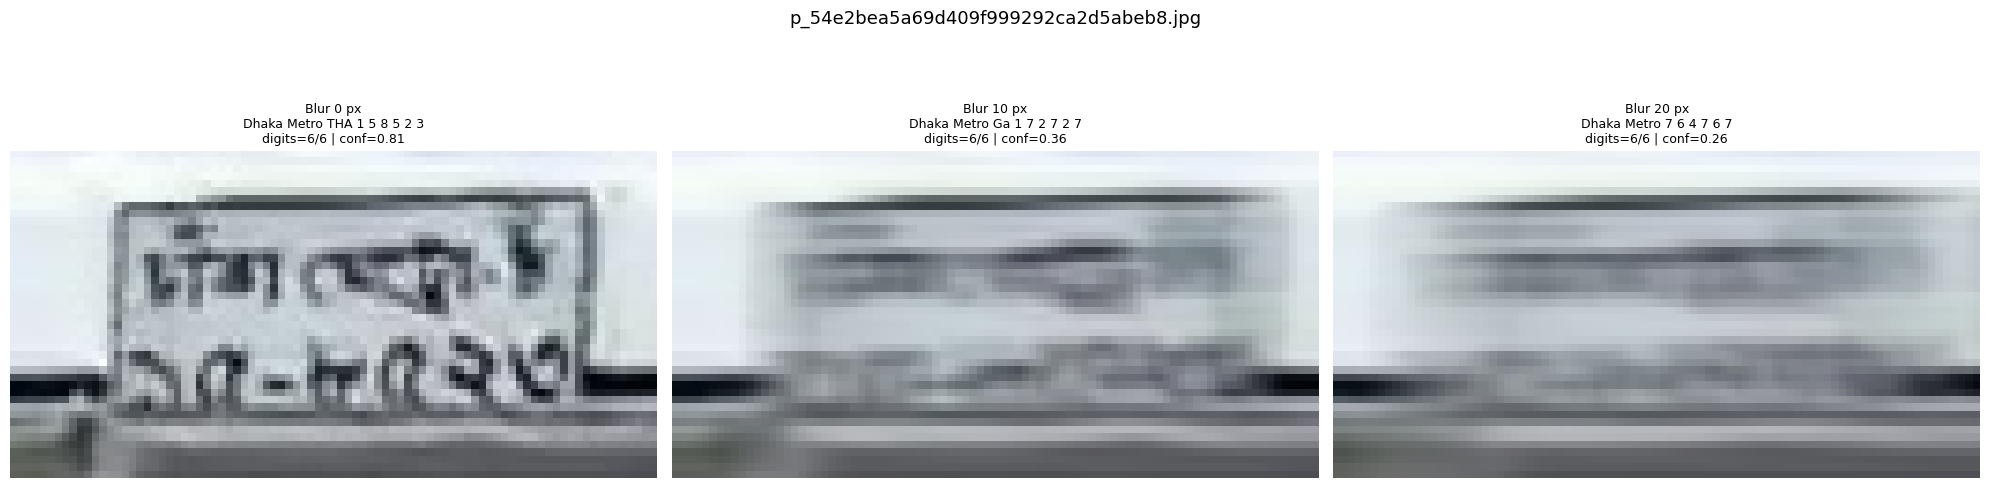

Saved comparison: /kaggle/working/bangla_instant_demo/p_54e2bea5a69d409f999292ca2d5abeb8_comparison.png
IMAGE 12/31: p_573af3ebc48a4186ba63f4b3ccd7fec6.jpg
Blur  0 px: Dhaka Metro Cha 5 3 9 4 6 7 | digits=6/6 | avg_conf=0.808
Blur 10 px: Dhaka Metro Ha 7 7 9 4 5 2 | digits=6/6 | avg_conf=0.382
Blur 20 px: Dhaka Metro U 7 7 7 9 2 2 | digits=6/6 | avg_conf=0.224
  CHECK: low confidence


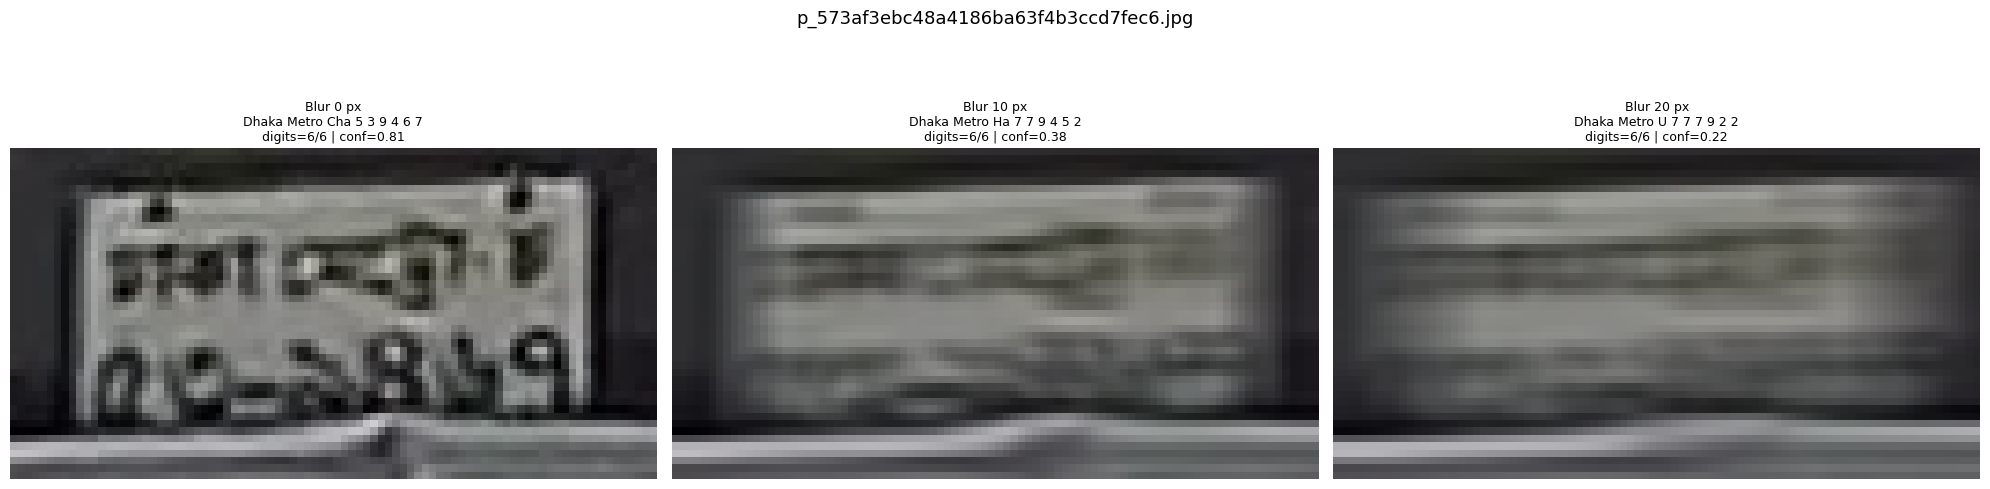

Saved comparison: /kaggle/working/bangla_instant_demo/p_573af3ebc48a4186ba63f4b3ccd7fec6_comparison.png
IMAGE 13/31: p_577461673e8b4a45a038b1e92404a728.jpg
Blur  0 px: Dhaka Metro Ga 3 3 0 2 8 1 | digits=6/6 | avg_conf=0.900
Blur 10 px: Dhaka Metro Ga 3 3 0 2 8 1 | digits=6/6 | avg_conf=0.783
Blur 20 px: Dhaka Metro Ga 3 9 2 8 2 1 | digits=6/6 | avg_conf=0.365


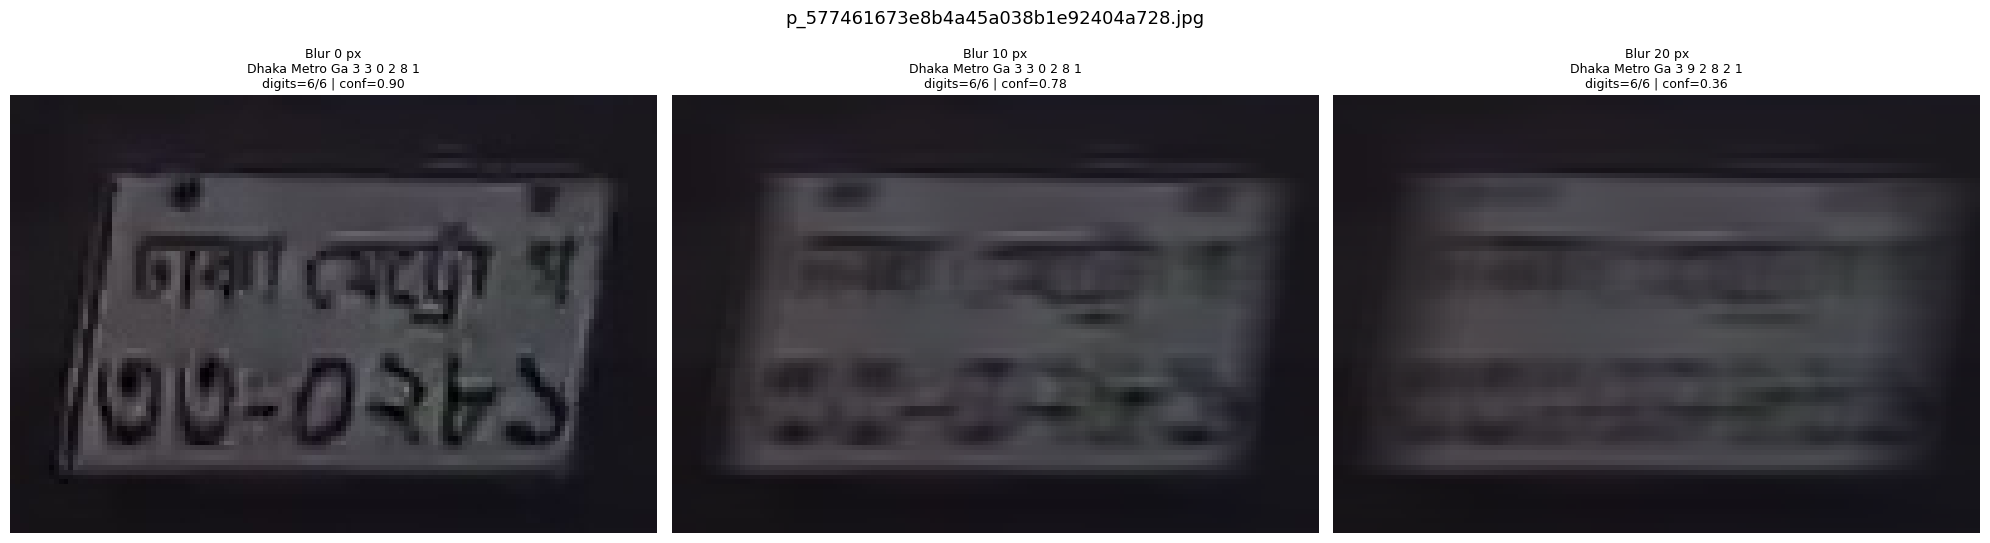

Saved comparison: /kaggle/working/bangla_instant_demo/p_577461673e8b4a45a038b1e92404a728_comparison.png
IMAGE 14/31: p_5be0d9c0cca2471399af830e7cbe9182.jpg
Blur  0 px: Dhaka Metro Ta 1 2 7 9 5 1 | digits=6/6 | avg_conf=0.858
Blur 10 px: Dhaka Metro Ga 1 2 7 9 5 1 | digits=6/6 | avg_conf=0.661
Blur 20 px: Dhaka Metro Ga 1 7 1 7 7 7 | digits=6/6 | avg_conf=0.287
  CHECK: low confidence


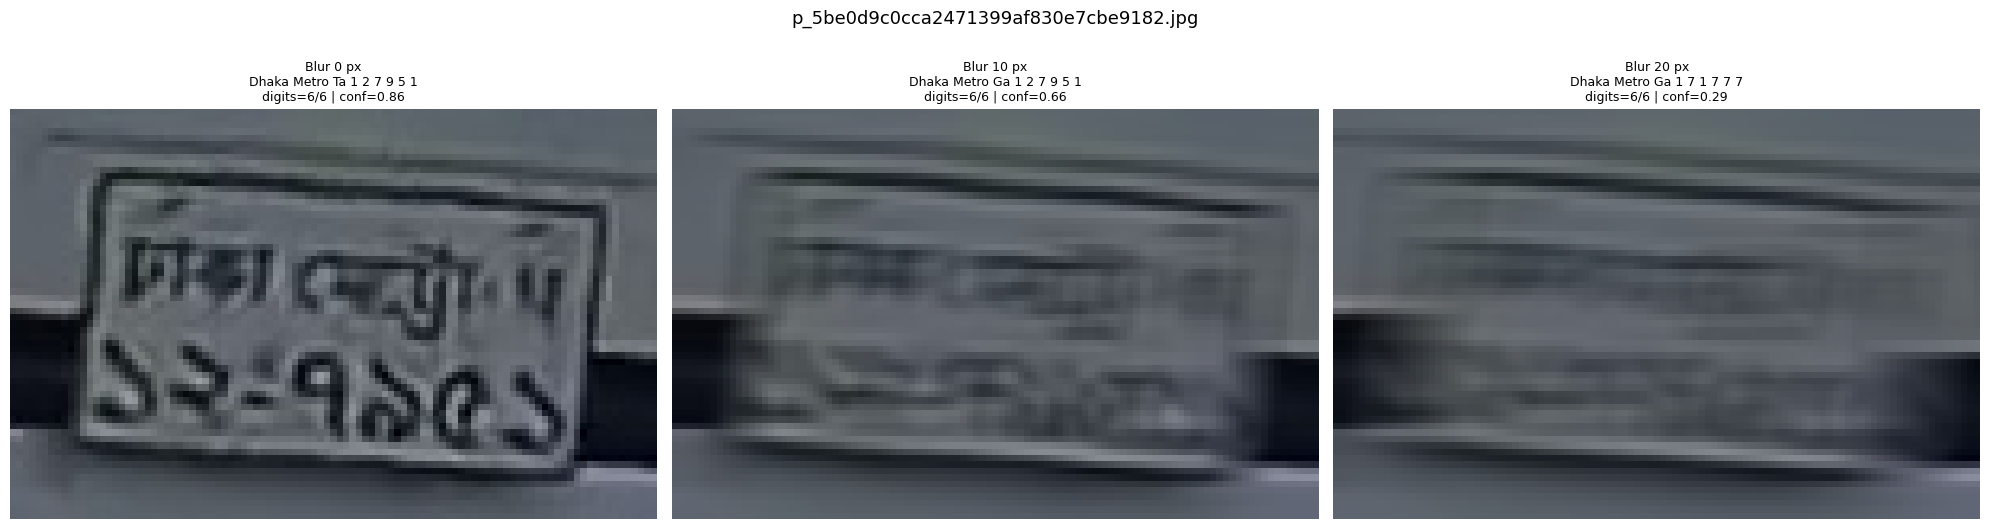

Saved comparison: /kaggle/working/bangla_instant_demo/p_5be0d9c0cca2471399af830e7cbe9182_comparison.png
IMAGE 15/31: p_6b6a7106f5e34dd3af109afe9822480c.jpg
Blur  0 px: Dhaka Metro Ga 3 2 2 1 9 1 | digits=6/6 | avg_conf=0.874
Blur 10 px: Dhaka Metro Ga 3 2 2 1 9 1 | digits=6/6 | avg_conf=0.586
Blur 20 px: Dhaka Metro Ga 7 2 9 8 7 6 | digits=6/6 | avg_conf=0.242
  CHECK: low confidence


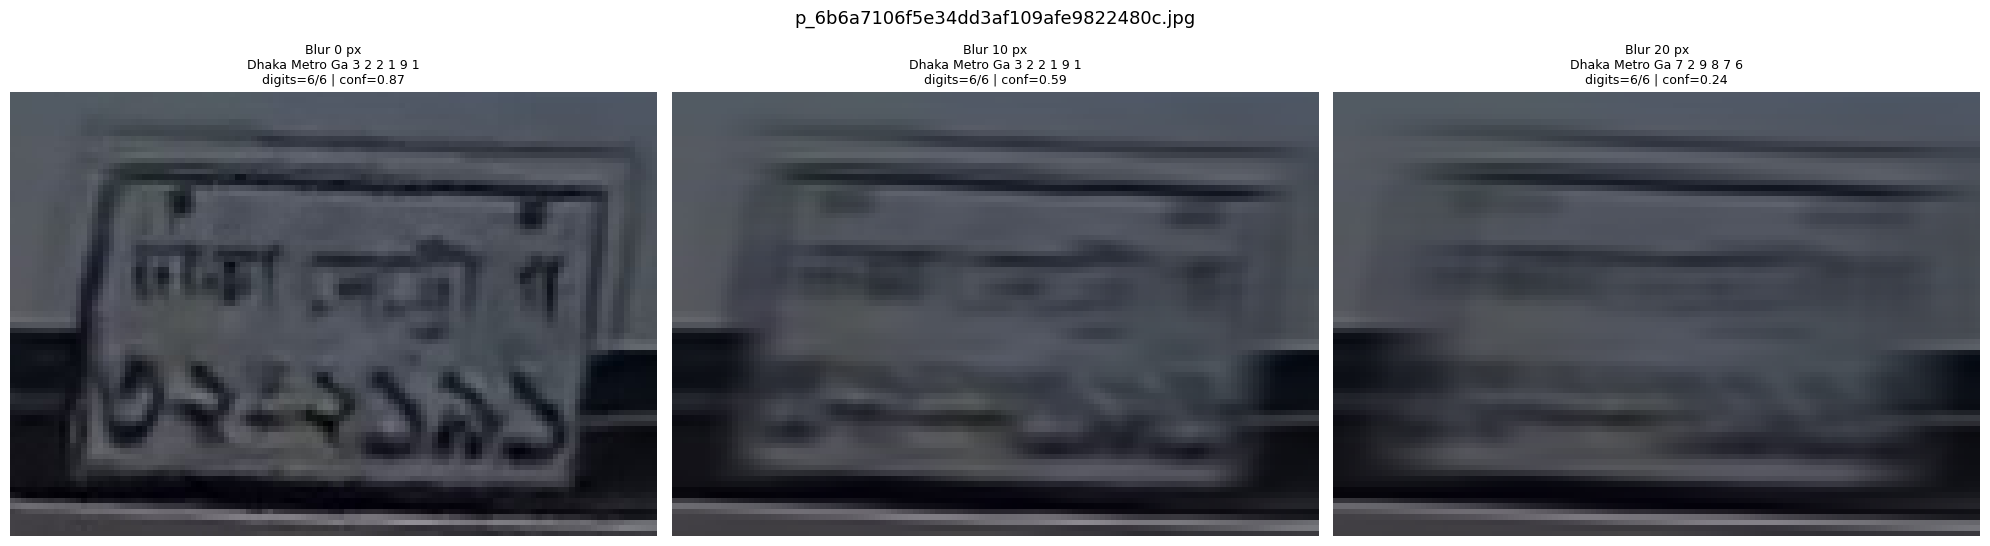

Saved comparison: /kaggle/working/bangla_instant_demo/p_6b6a7106f5e34dd3af109afe9822480c_comparison.png
IMAGE 16/31: p_6cf3f312b9f04ffab5c19baae37a5d4f.jpg
Blur  0 px: Dhaka Metro Gha 1 2 8 2 2 2 | digits=6/6 | avg_conf=0.866
Blur 10 px: Dhaka Metro Gha 1 2 8 2 2 2 | digits=6/6 | avg_conf=0.803
Blur 20 px: Dhaka Metro U 1 1 2 2 2 2 | digits=6/6 | avg_conf=0.426


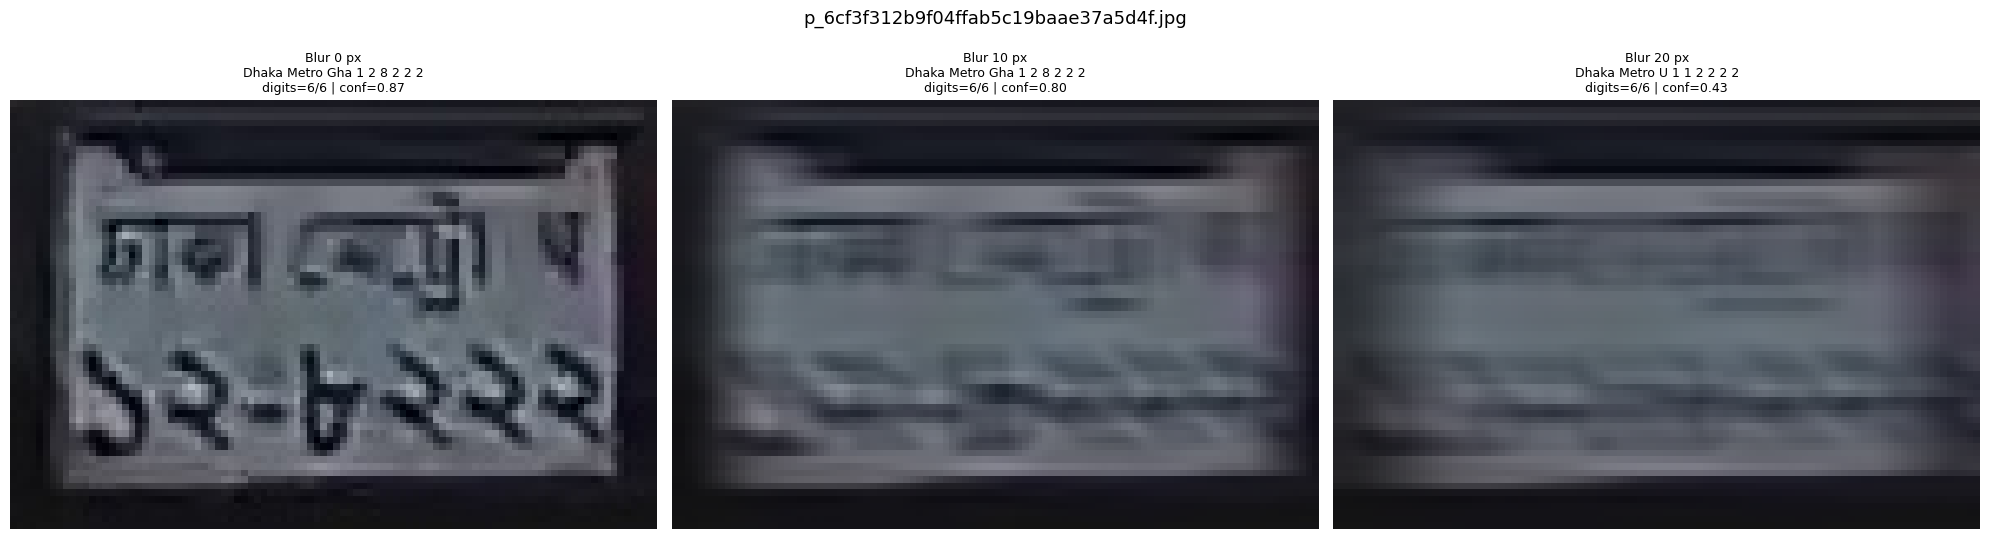

Saved comparison: /kaggle/working/bangla_instant_demo/p_6cf3f312b9f04ffab5c19baae37a5d4f_comparison.png
IMAGE 17/31: p_971c46a7ea77432c9ba450fbf210fce4.jpg
Blur  0 px: Dhaka Metro Ha 1 1 9 5 8 8 | digits=6/6 | avg_conf=0.707
Blur 10 px: Dhaka Metro Tha 1 1 9 5 6 8 | digits=6/6 | avg_conf=0.372
Blur 20 px: Dhaka Metro Tha 1 | digits=1/6 | avg_conf=0.214
  CHECK: 1/6 digits detected, low confidence


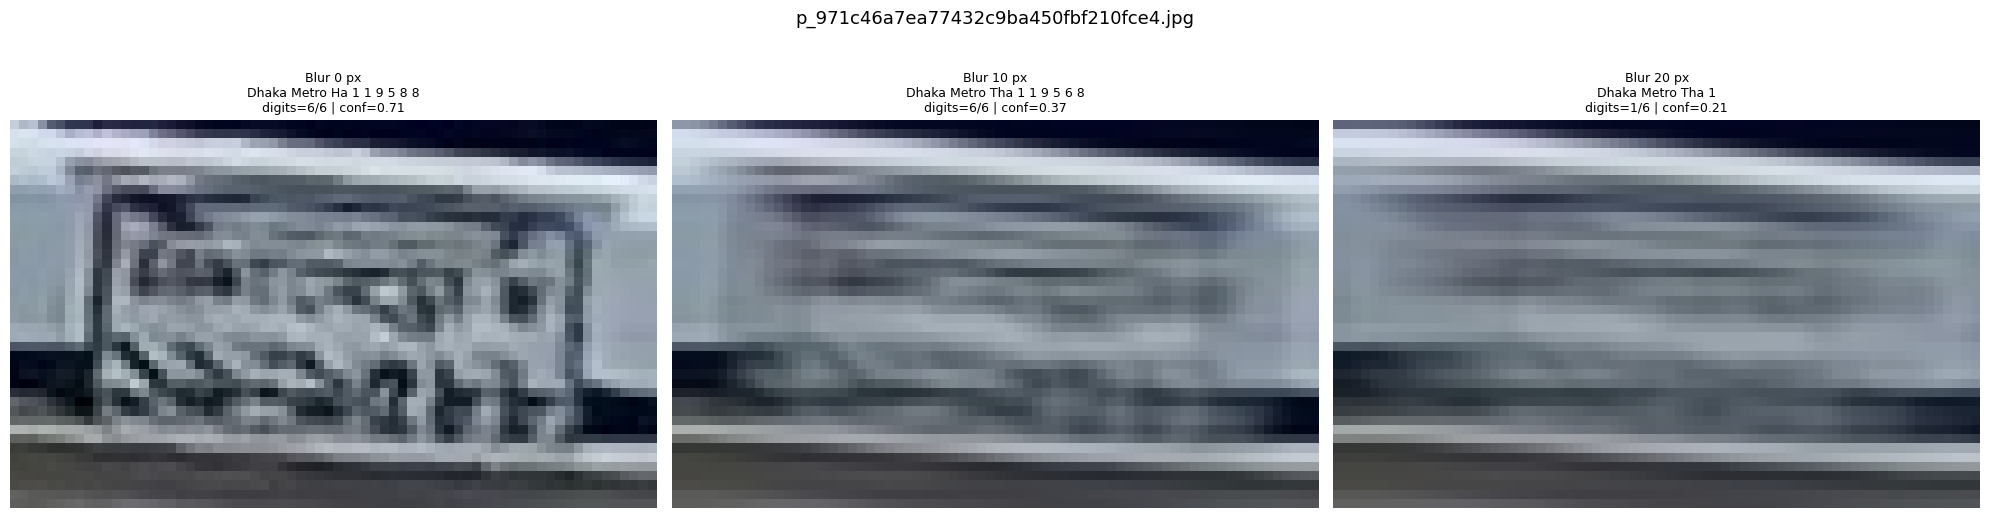

Saved comparison: /kaggle/working/bangla_instant_demo/p_971c46a7ea77432c9ba450fbf210fce4_comparison.png
IMAGE 18/31: p_ac6f0193f0b646e787a162196626dda6.jpg
Blur  0 px: Dhaka Metro Jha 1 2 0 2 6 4 | digits=6/6 | avg_conf=0.897
Blur 10 px: Dhaka Metro Jha 1 2 0 2 6 4 | digits=6/6 | avg_conf=0.797
Blur 20 px: Dhaka Metro 5 1 2 5 2 4 | digits=6/6 | avg_conf=0.363
  CHECK: series label missing


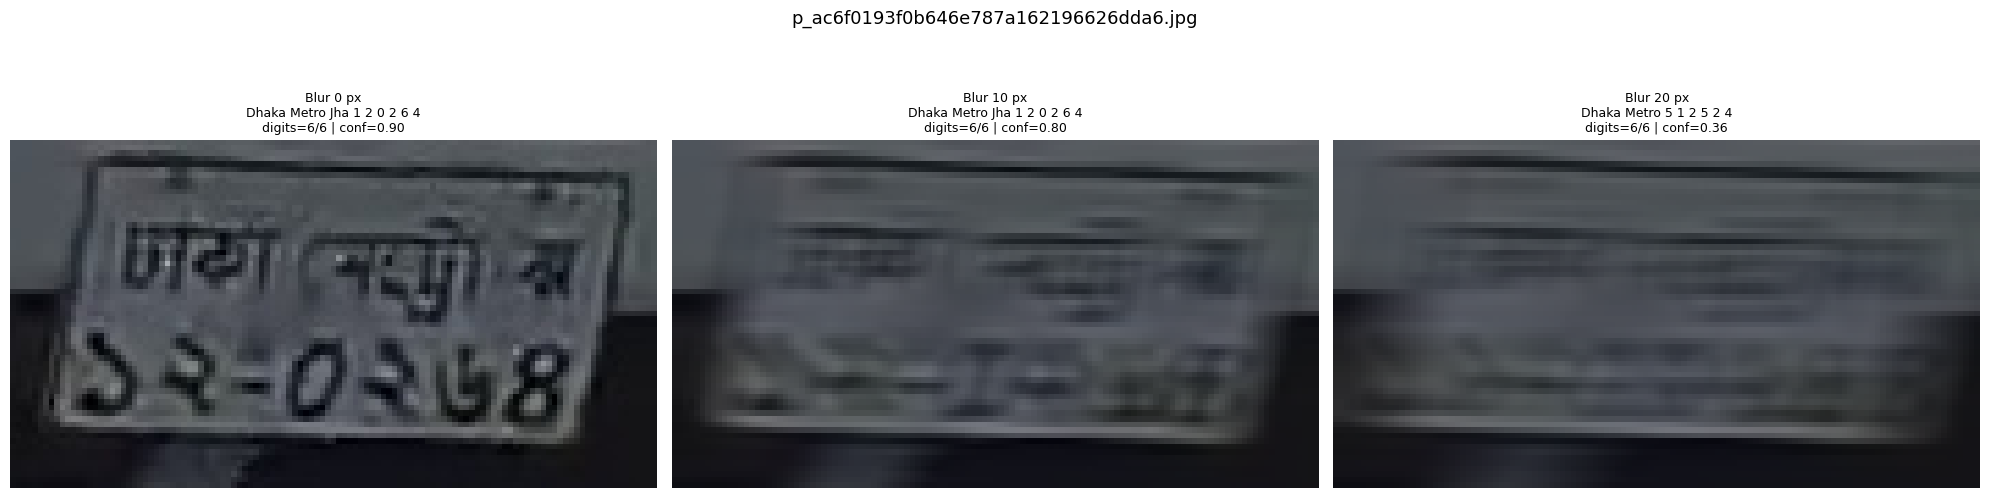

Saved comparison: /kaggle/working/bangla_instant_demo/p_ac6f0193f0b646e787a162196626dda6_comparison.png
IMAGE 19/31: p_bb77f25ee36e470f92bd6bd433b9f94f.jpg
Blur  0 px: Dhaka Metro Ta 5 0 2 8 1 9 | digits=6/6 | avg_conf=0.712
Blur 10 px: Dhaka Metro Ta 5 0 2 7 9 9 | digits=6/6 | avg_conf=0.540
Blur 20 px: Dhaka Metro Ta 7 2 7 7 9 9 | digits=6/6 | avg_conf=0.238
  CHECK: low confidence


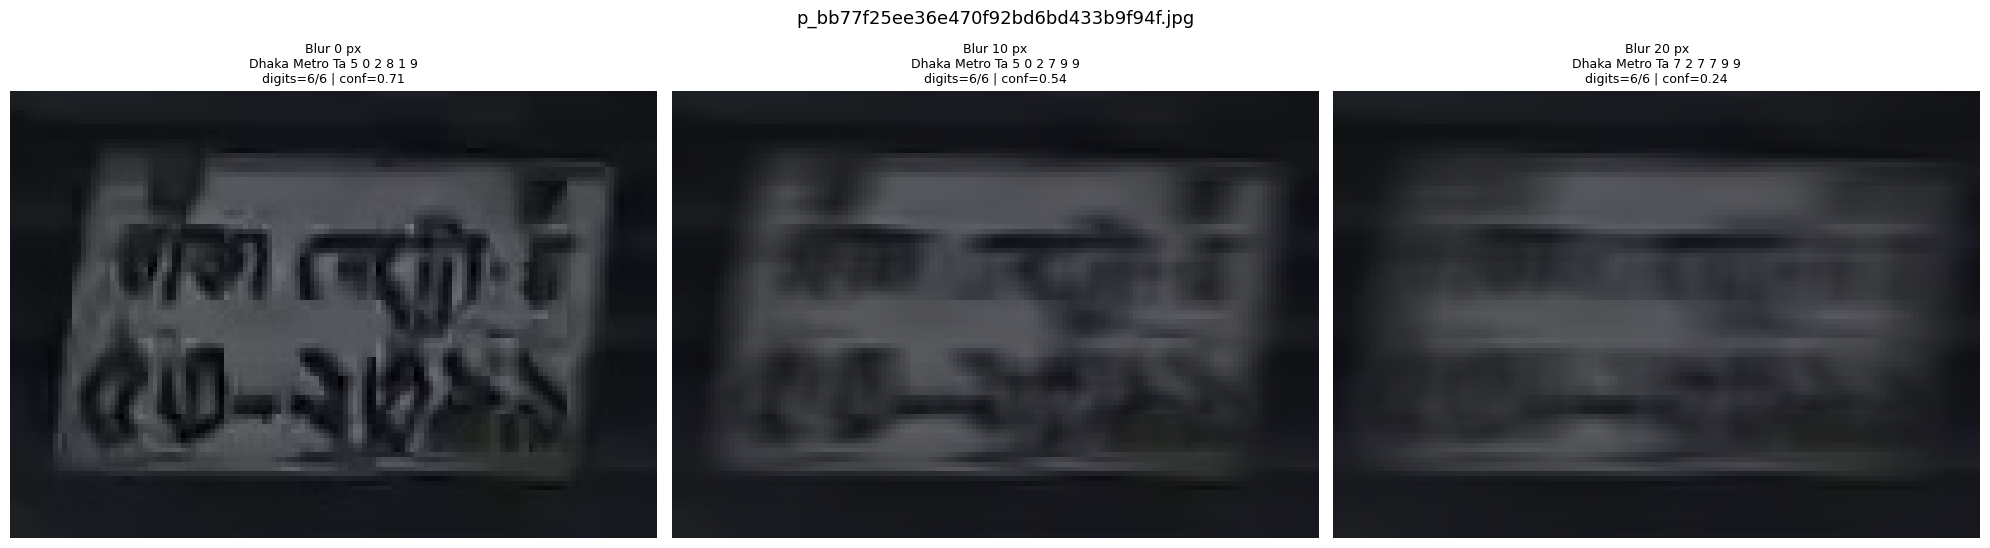

Saved comparison: /kaggle/working/bangla_instant_demo/p_bb77f25ee36e470f92bd6bd433b9f94f_comparison.png
IMAGE 20/31: p_c206f1d0947341d9a12a6c01937b5a45.jpg
Blur  0 px: Dhaka Metro Ta 1 9 4 1 1 1 | digits=6/6 | avg_conf=0.807
Blur 10 px: Dhaka Metro 1 9 4 1 1 1 | digits=6/6 | avg_conf=0.633
  CHECK: series label missing
Blur 20 px: Dhaka Metro 1 6 4 5 2 1 | digits=6/6 | avg_conf=0.351
  CHECK: series label missing


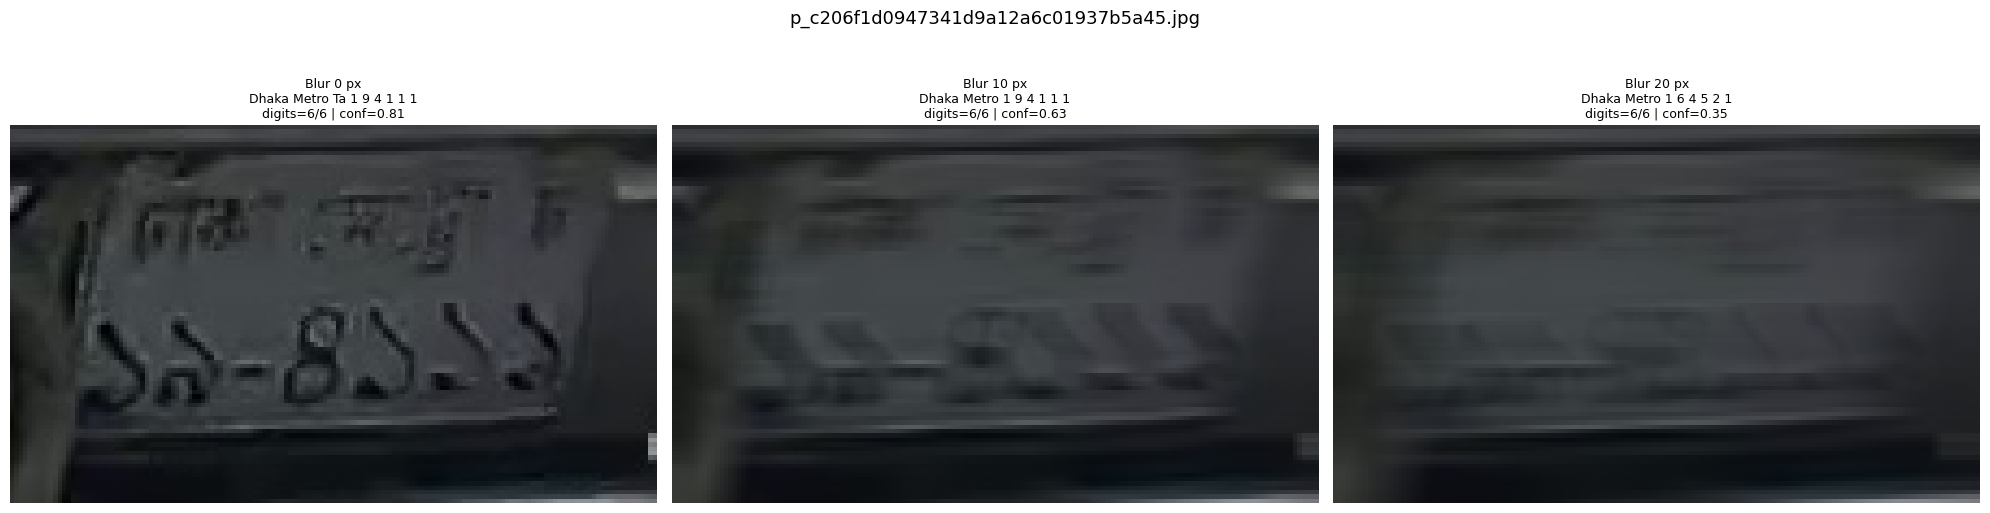

Saved comparison: /kaggle/working/bangla_instant_demo/p_c206f1d0947341d9a12a6c01937b5a45_comparison.png
IMAGE 21/31: p_c71a8ac9e0104c4c94263ddf2120a1e2.jpg
Blur  0 px: Dhaka Metro Ha 3 3 2 5 8 7 | digits=6/6 | avg_conf=0.729
Blur 10 px: Dhaka Metro Ga 8 8 2 7 8 7 | digits=6/6 | avg_conf=0.367
Blur 20 px: Dhaka Metro 7 5 2 7 6 7 | digits=6/6 | avg_conf=0.163
  CHECK: series label missing, low confidence


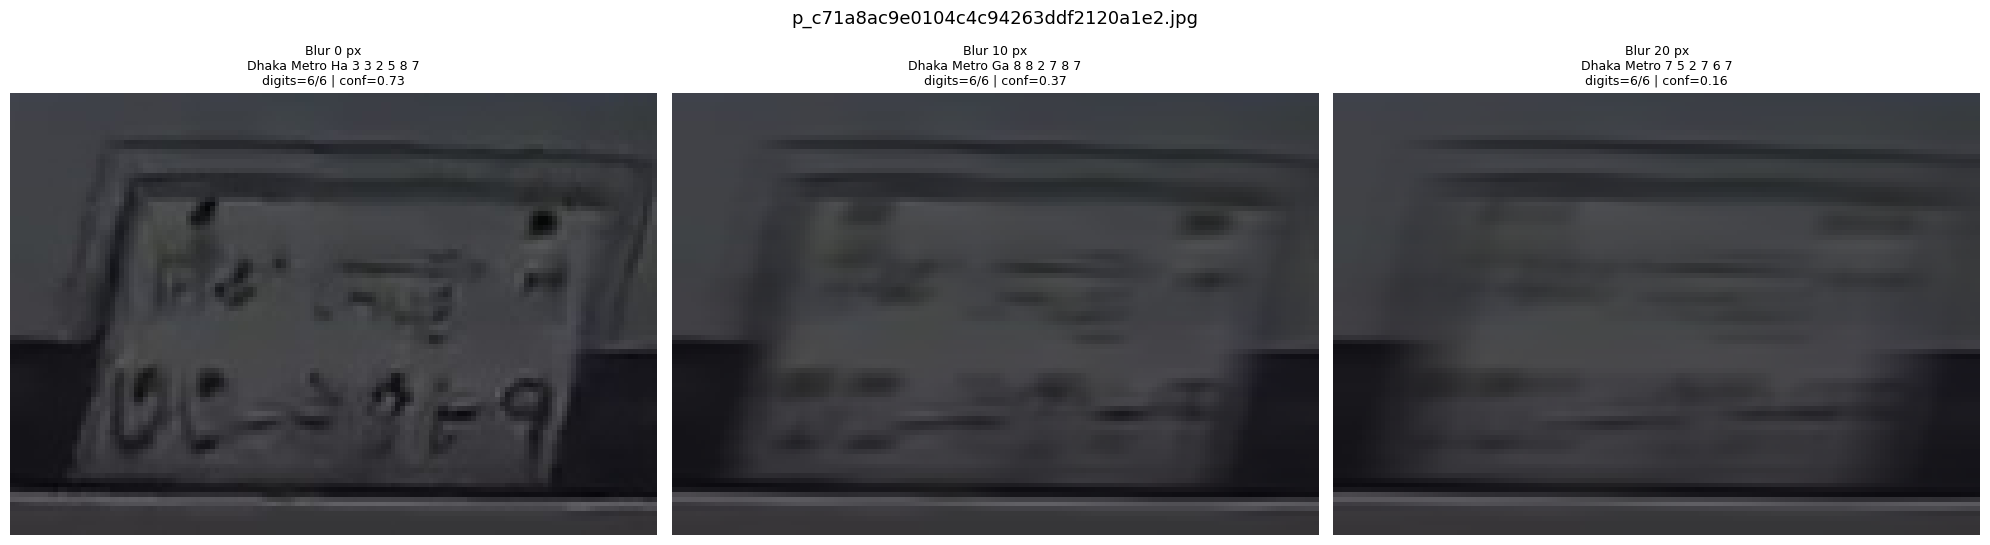

Saved comparison: /kaggle/working/bangla_instant_demo/p_c71a8ac9e0104c4c94263ddf2120a1e2_comparison.png
IMAGE 22/31: p_caebf29094994d8a9b18e5f26d98d45d.jpg
Blur  0 px: Dhaka Metro Ga 3 1 2 8 9 9 | digits=6/6 | avg_conf=0.887
Blur 10 px: Dhaka Metro Ga 3 1 2 8 8 2 | digits=6/6 | avg_conf=0.529
Blur 20 px: Dhaka Metro Ga 2 6 4 8 8 9 | digits=6/6 | avg_conf=0.222
  CHECK: low confidence


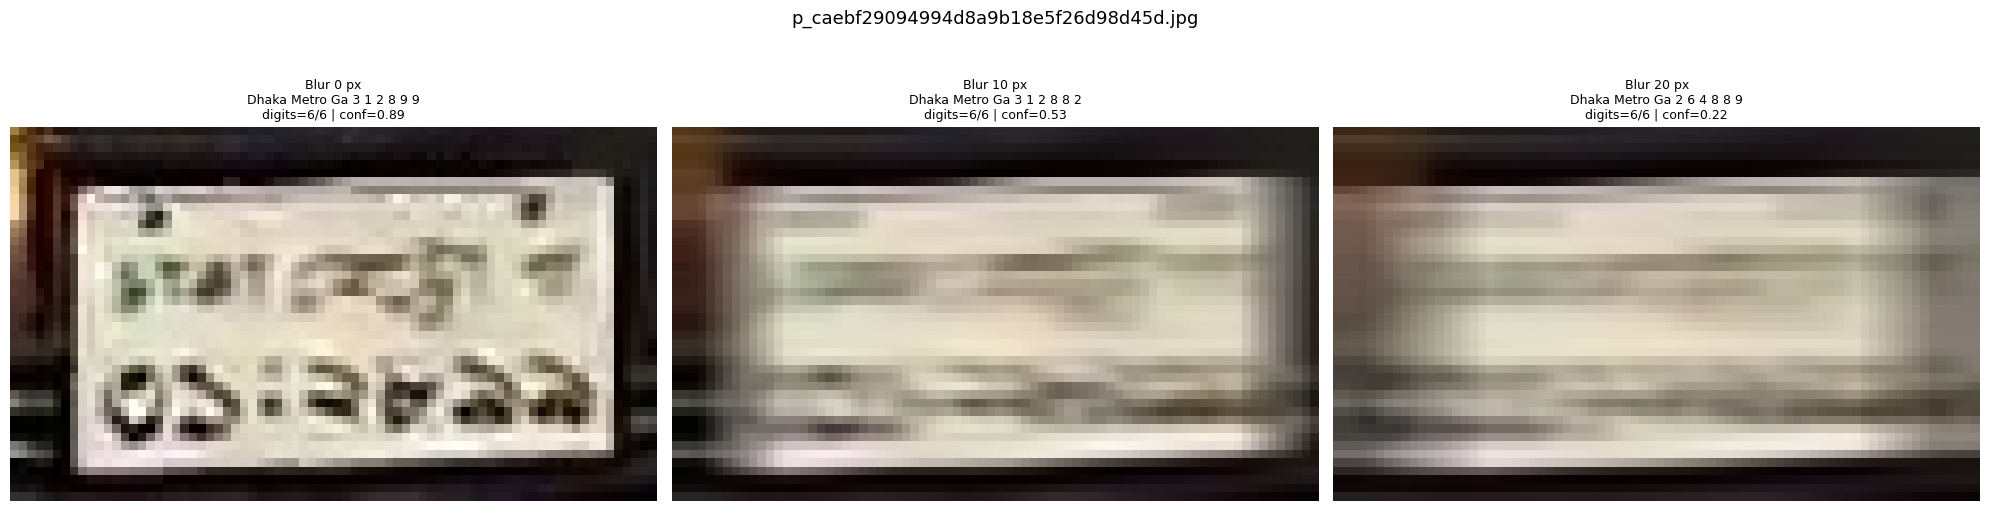

Saved comparison: /kaggle/working/bangla_instant_demo/p_caebf29094994d8a9b18e5f26d98d45d_comparison.png
IMAGE 23/31: p_cc35588af7af48f389969a953e37b394.jpg
Blur  0 px: Dhaka Metro THA 1 3 5 6 6 5 | digits=6/6 | avg_conf=0.881
Blur 10 px: Dhaka Metro Ta 1 3 5 6 6 0 | digits=6/6 | avg_conf=0.675
Blur 20 px: Dhaka Metro Ga 1 3 9 7 8 4 | digits=6/6 | avg_conf=0.368


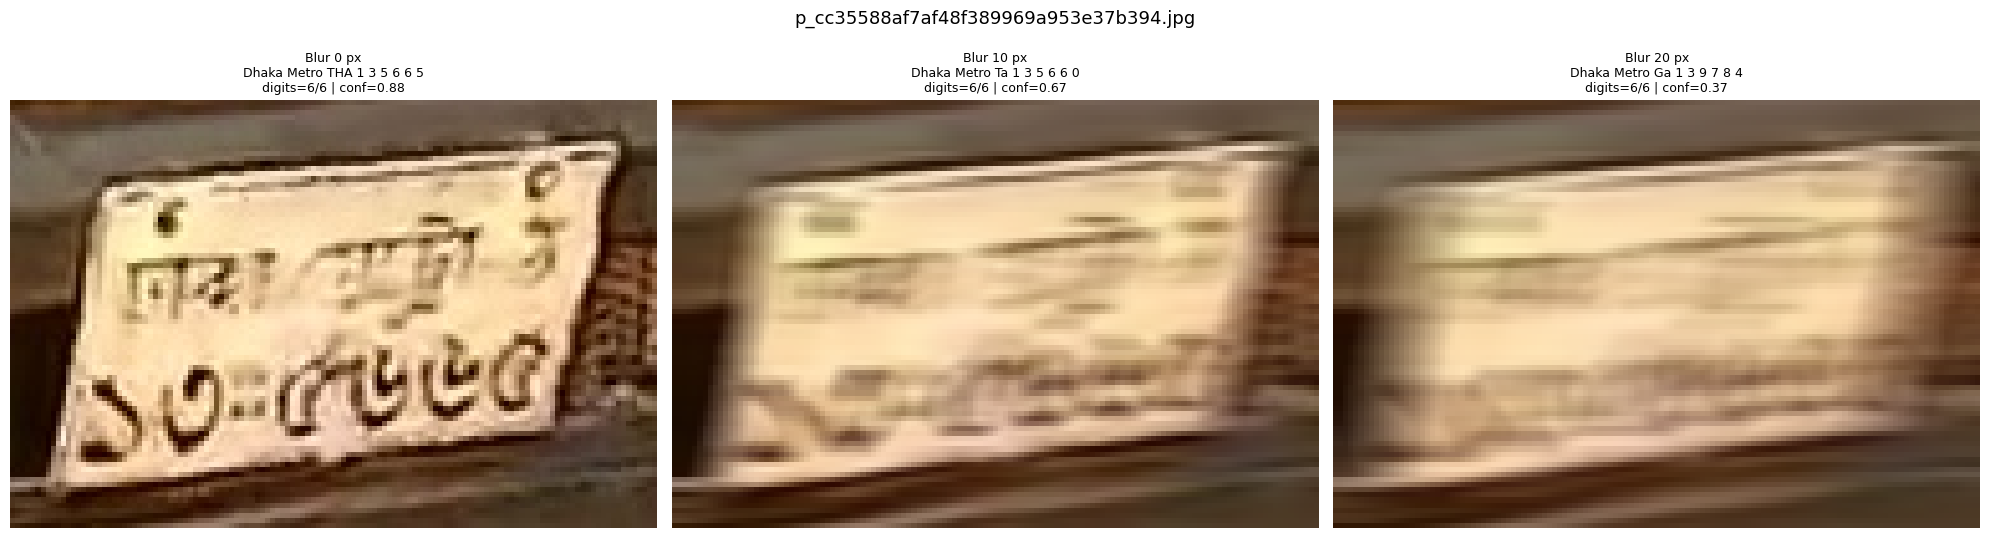

Saved comparison: /kaggle/working/bangla_instant_demo/p_cc35588af7af48f389969a953e37b394_comparison.png
IMAGE 24/31: p_d3335062b53a447d8c2668c69f6c2670.jpg
Blur  0 px: Metro U 1 1 0 0 6 2 | digits=6/6 | avg_conf=0.653
  CHECK: location missing
Blur 10 px: Kurigram 1 1 0 4 2 1 | digits=6/6 | avg_conf=0.253
  CHECK: Metro missing, series label missing, low confidence
Blur 20 px: Jessore 1 7 9 | digits=3/6 | avg_conf=0.128
  CHECK: 3/6 digits detected, Metro missing, series label missing, low confidence


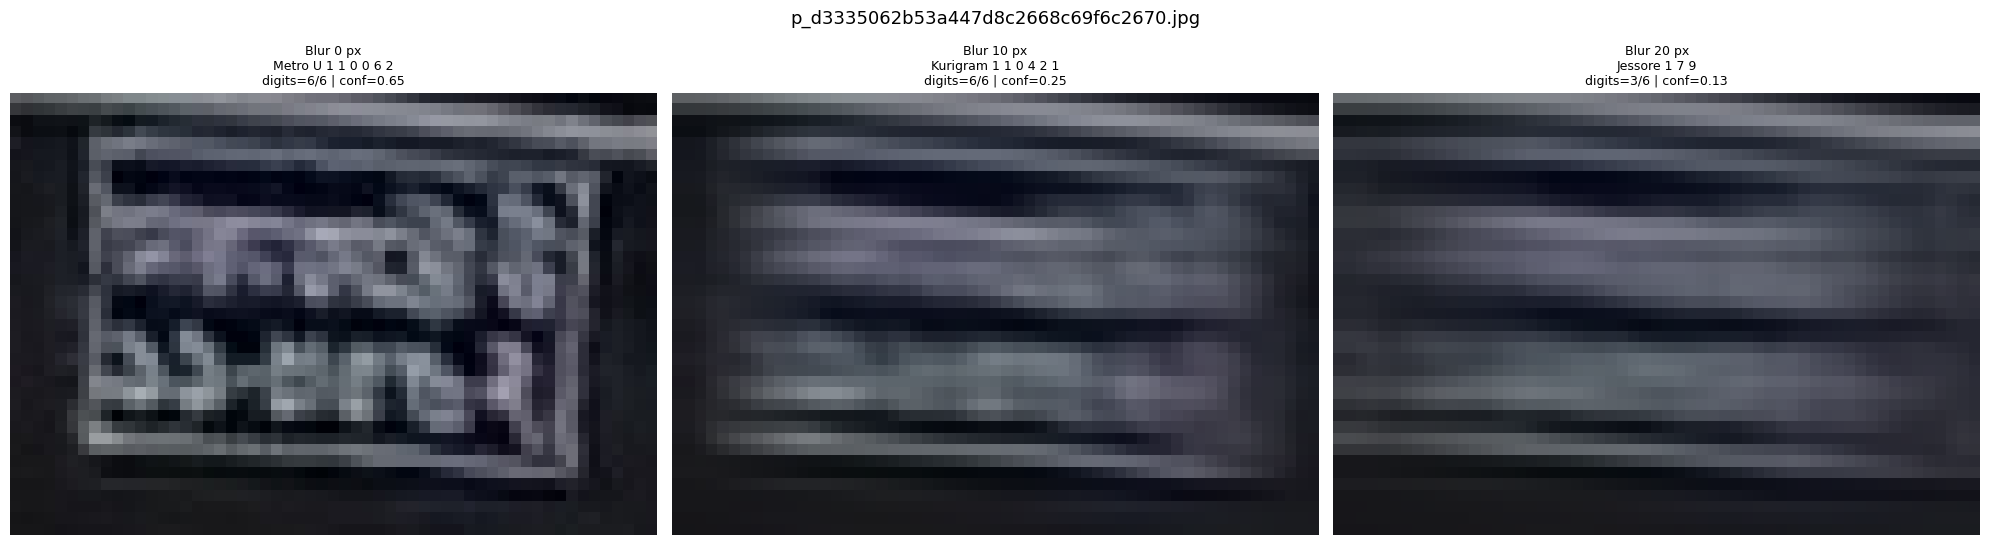

Saved comparison: /kaggle/working/bangla_instant_demo/p_d3335062b53a447d8c2668c69f6c2670_comparison.png
IMAGE 25/31: p_d9c93470b10f44e4b7fb0cbf40cba7da.jpg
Blur  0 px: Dhaka Metro Cha 5 6 6 5 1 6 | digits=6/6 | avg_conf=0.861
Blur 10 px: Dhaka Metro Gha 6 2 6 5 1 2 | digits=6/6 | avg_conf=0.434
Blur 20 px: Dhaka Metro Ga 4 2 2 6 6 6 | digits=6/6 | avg_conf=0.241
  CHECK: low confidence


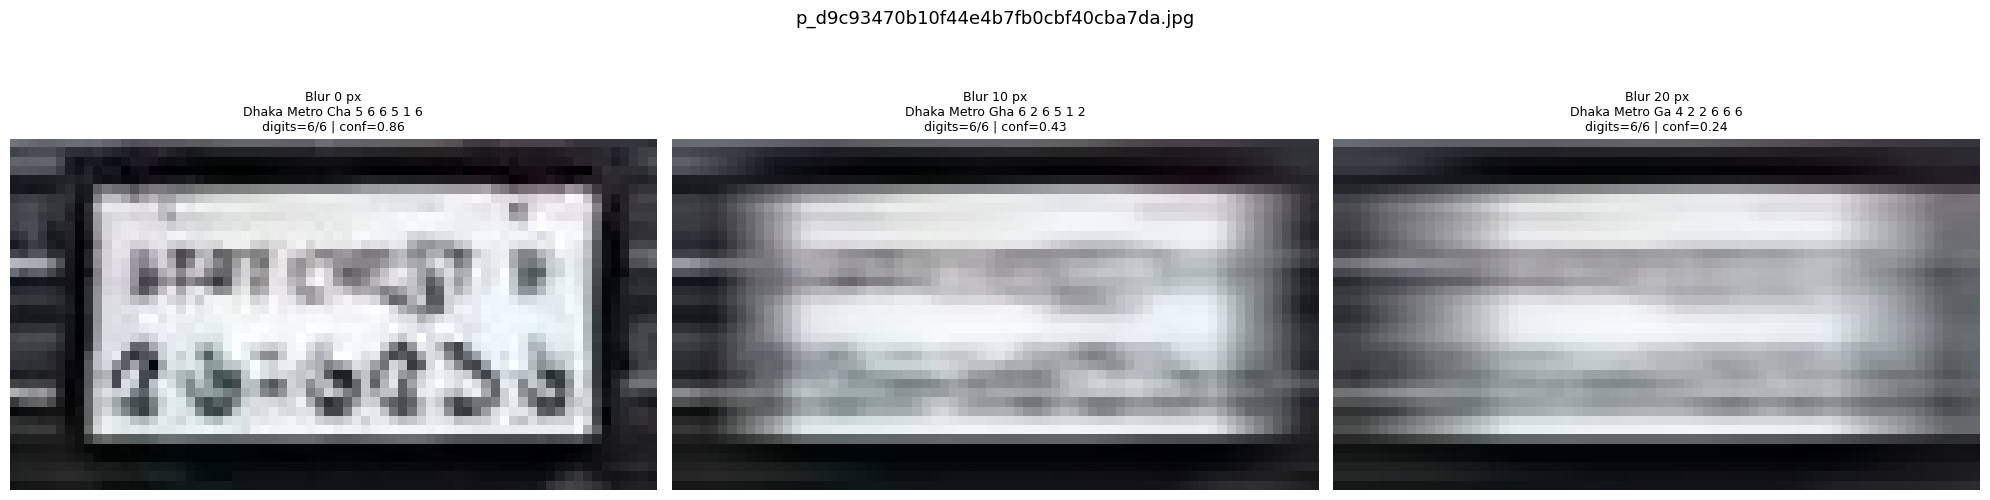

Saved comparison: /kaggle/working/bangla_instant_demo/p_d9c93470b10f44e4b7fb0cbf40cba7da_comparison.png
IMAGE 26/31: p_db5800369f534b77ab94c8044ce9f7c5.jpg
Blur  0 px: Dhaka Metro Ta 1 6 2 8 0 3 | digits=6/6 | avg_conf=0.731
Blur 10 px: Dhaka Metro 1 5 4 2 1 1 | digits=6/6 | avg_conf=0.380
  CHECK: series label missing
Blur 20 px: Dhaka Metro 1 1 9 8 7 7 | digits=6/6 | avg_conf=0.131
  CHECK: series label missing, low confidence


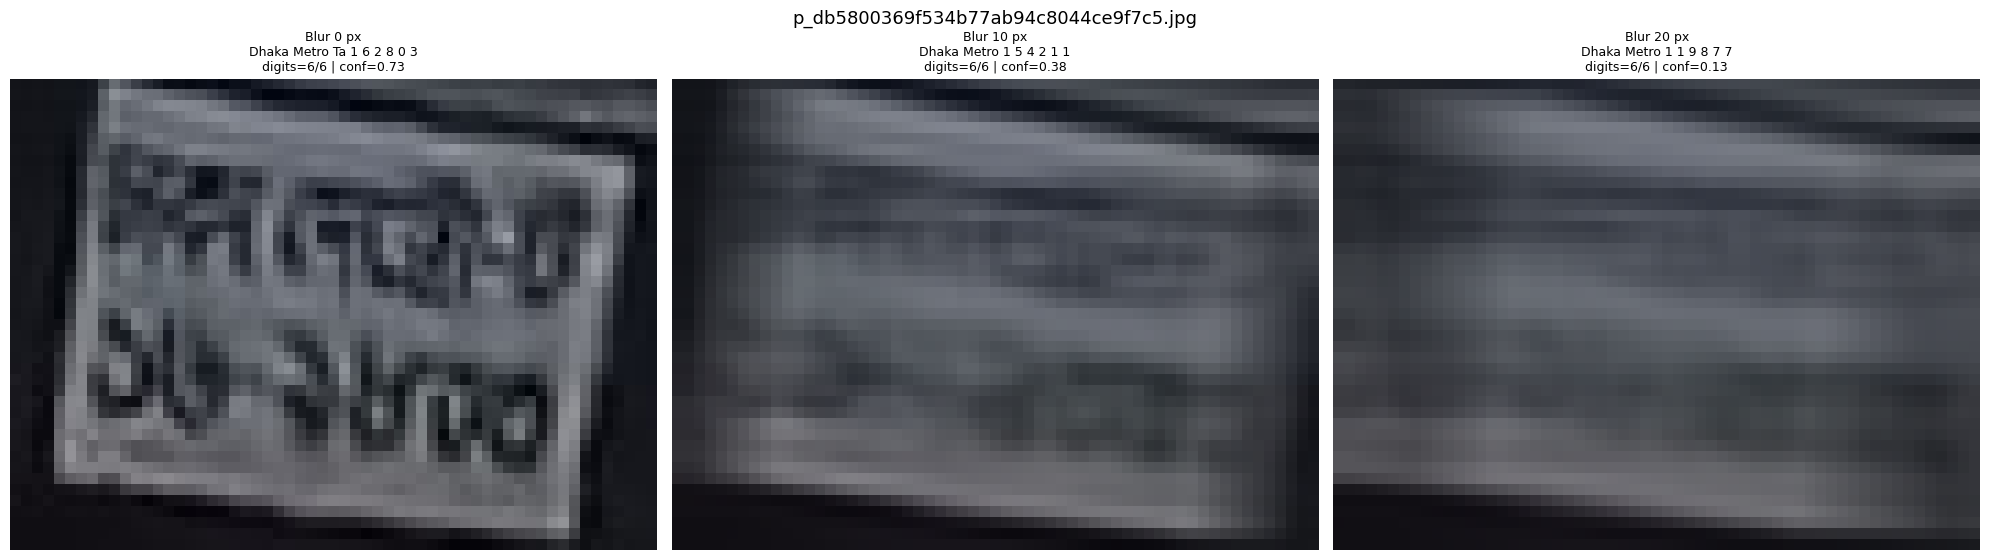

Saved comparison: /kaggle/working/bangla_instant_demo/p_db5800369f534b77ab94c8044ce9f7c5_comparison.png
IMAGE 27/31: p_dcdec58b9ae04665a23da87abbe9c9f4.jpg
Blur  0 px: Chatto Metro Dha 8 1 4 2 9 1 | digits=6/6 | avg_conf=0.848
Blur 10 px: Chatto Metro Dha 8 1 4 2 9 1 | digits=6/6 | avg_conf=0.823
Blur 20 px: Chatto Metro 0 1 1 4 7 9 | digits=6/6 | avg_conf=0.463
  CHECK: series label missing


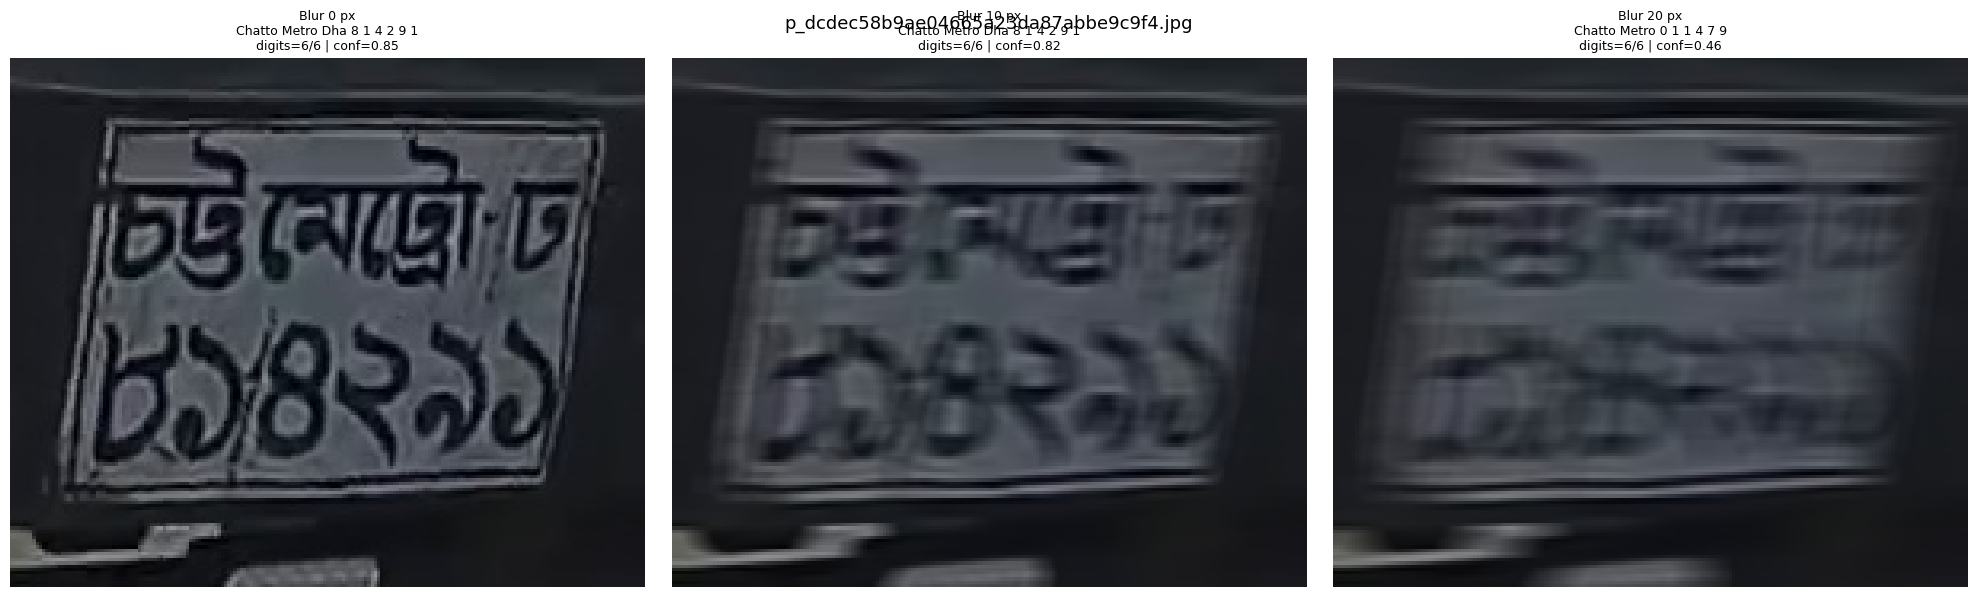

Saved comparison: /kaggle/working/bangla_instant_demo/p_dcdec58b9ae04665a23da87abbe9c9f4_comparison.png
IMAGE 28/31: p_eec2e46a849b40bfa16230424b5ef369.jpg
Blur  0 px: Dhaka Metro Ga 2 7 7 7 8 4 | digits=6/6 | avg_conf=0.863
Blur 10 px: Dhaka Metro Ga 2 7 7 7 8 4 | digits=6/6 | avg_conf=0.743
Blur 20 px: Dhaka Metro Ga 2 7 7 7 8 2 | digits=6/6 | avg_conf=0.319
  CHECK: low confidence


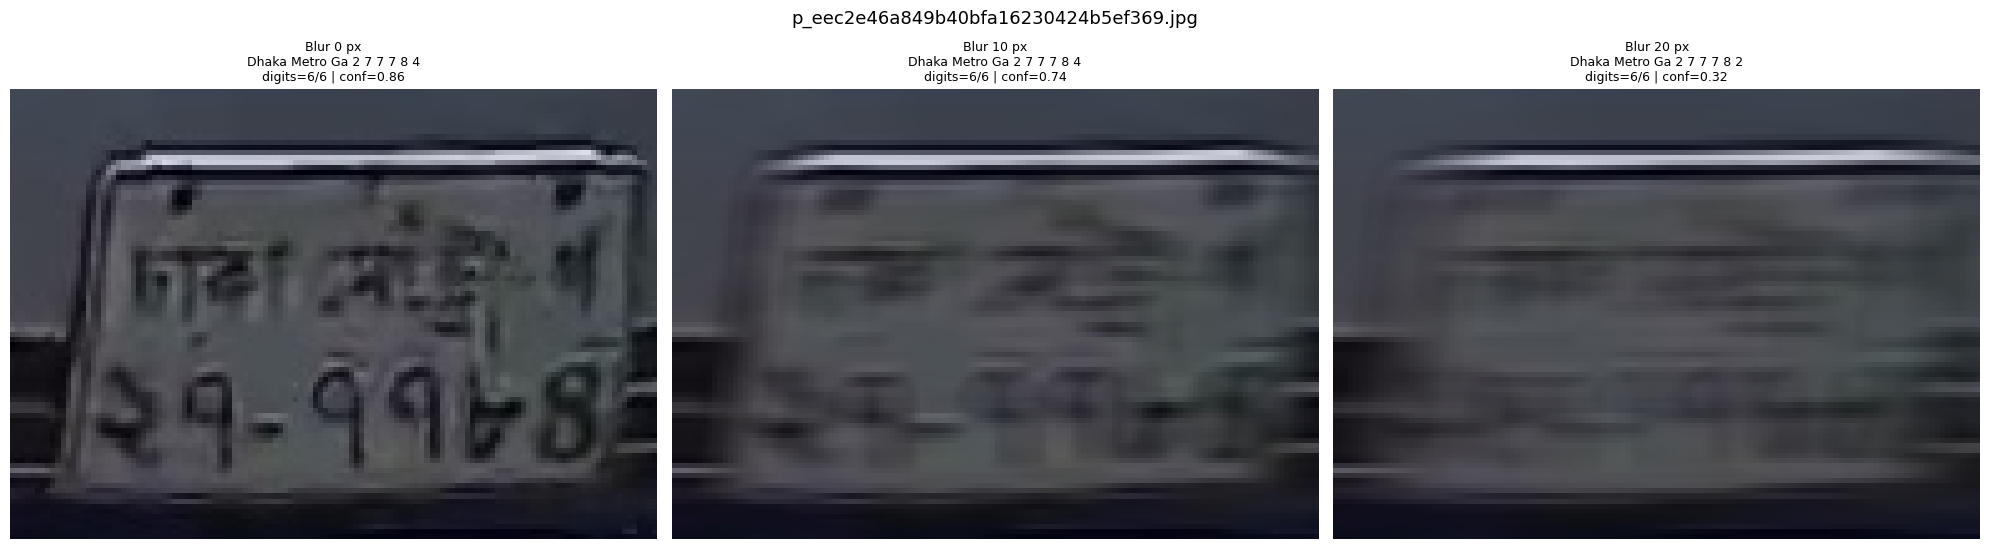

Saved comparison: /kaggle/working/bangla_instant_demo/p_eec2e46a849b40bfa16230424b5ef369_comparison.png
IMAGE 29/31: p_ef8c2dfab39e46dfb6b5960041990bc7.jpg
Blur  0 px: Dhaka Metro Ga 4 7 7 1 7 0 | digits=6/6 | avg_conf=0.764
Blur 10 px: Dhaka Metro Tha 7 7 5 7 7 7 | digits=6/6 | avg_conf=0.331
  CHECK: low confidence
Blur 20 px: Dhaka 7 7 7 7 7 1 | digits=6/6 | avg_conf=0.176
  CHECK: Metro missing, series label missing, low confidence


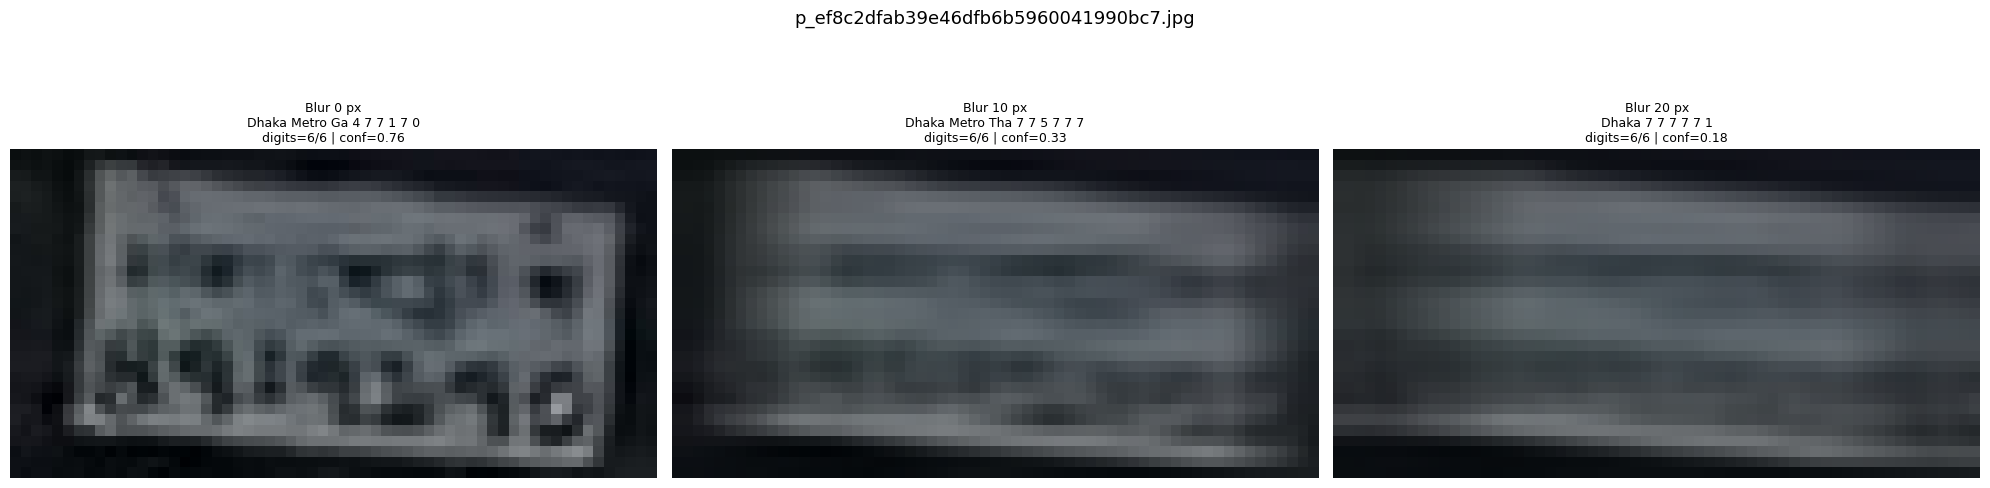

Saved comparison: /kaggle/working/bangla_instant_demo/p_ef8c2dfab39e46dfb6b5960041990bc7_comparison.png
IMAGE 30/31: p_f2d9e3e7298045c9925d739336ec668e.jpg
Blur  0 px: Dhaka Metro Ga 3 1 3 3 5 3 | digits=6/6 | avg_conf=0.747
Blur 10 px: Dhaka Metro Ga 2 6 6 7 7 7 | digits=6/6 | avg_conf=0.381
Blur 20 px: Dhaka Metro 7 7 8 8 7 7 | digits=6/6 | avg_conf=0.113
  CHECK: series label missing, low confidence


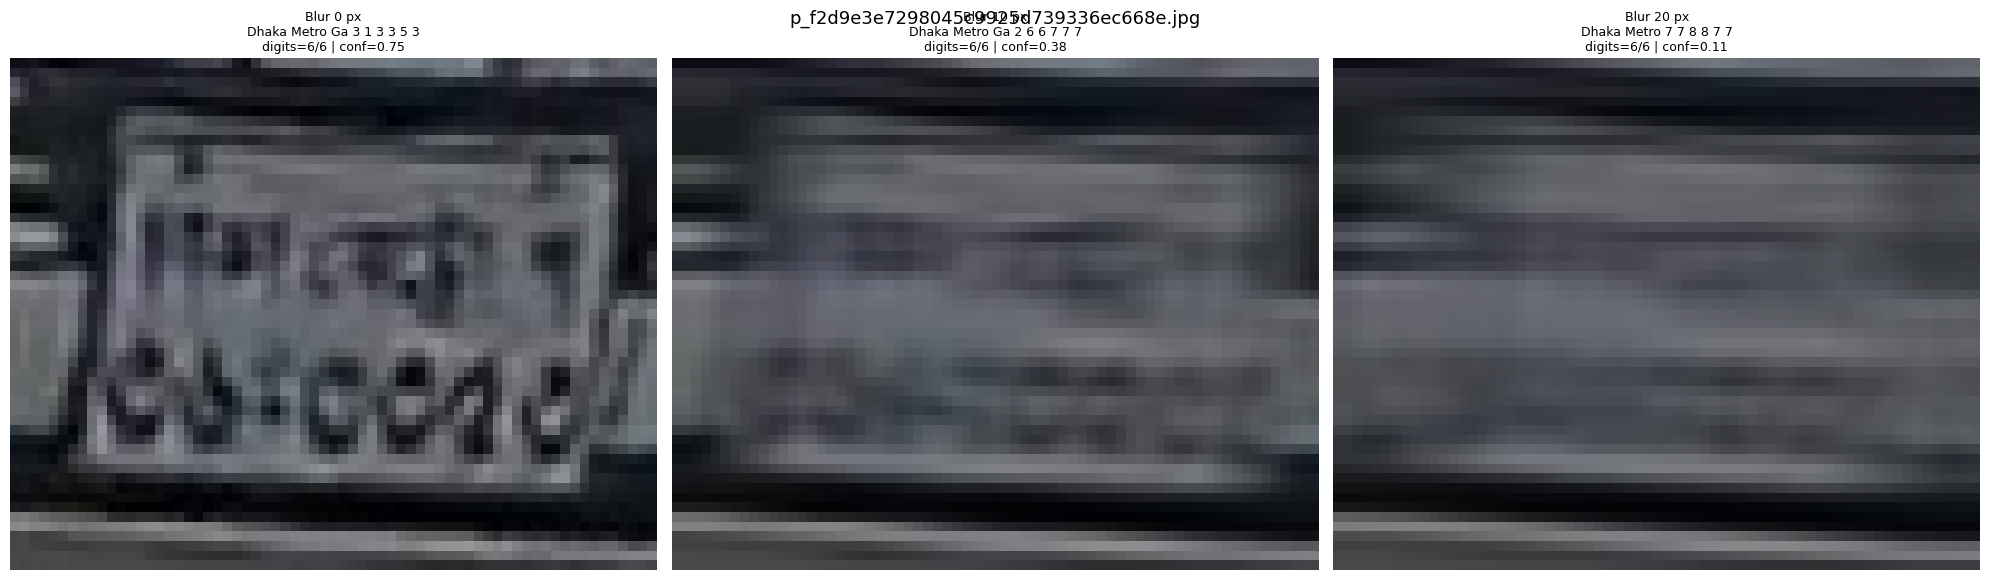

Saved comparison: /kaggle/working/bangla_instant_demo/p_f2d9e3e7298045c9925d739336ec668e_comparison.png
IMAGE 31/31: p_f76b04040d7c4a7e9991bddaf70b42bb.jpg
Blur  0 px: Dhaka Metro Gha 2 7 0 9 9 6 | digits=6/6 | avg_conf=0.857
Blur 10 px: Dhaka Metro Ga 2 7 0 9 9 6 | digits=6/6 | avg_conf=0.819
Blur 20 px: Dhaka Metro Ga 2 4 7 9 9 6 | digits=6/6 | avg_conf=0.362


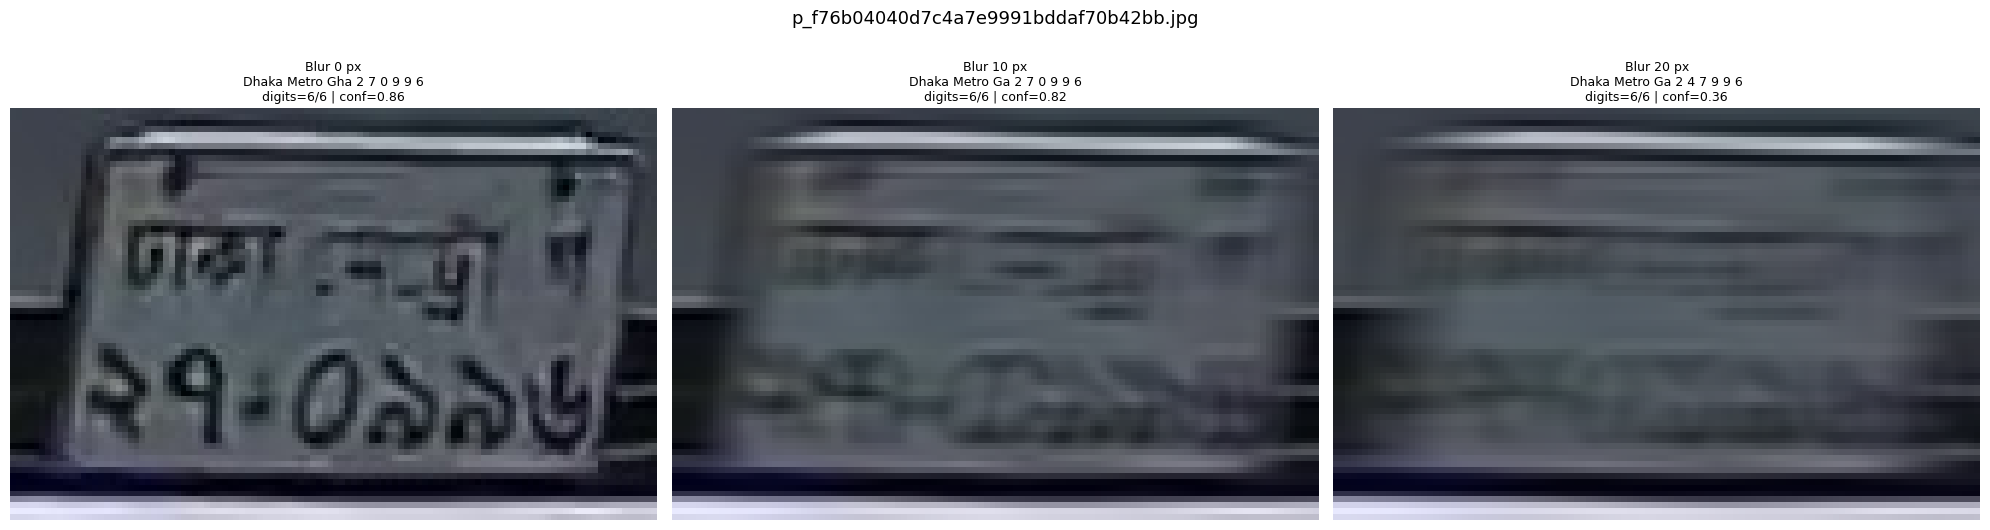

Saved comparison: /kaggle/working/bangla_instant_demo/p_f76b04040d7c4a7e9991bddaf70b42bb_comparison.png


NameError: name 'SUMMARY_CSV' is not defined

In [3]:
# CELL 3 — RUN THE INSTANT DEMO

model = YOLO(str(MODEL_PATH))
print("Final model loaded. Starting conservative instant demo...\n")
for i, name in enumerate(class_names):
    if name.strip().lower() in {"a", "ta", "ma", "na"}:
        print("Class ID:", i, "| Class name:", name)

image_files = sorted(
    p for p in DEMO_FOLDER.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)
if not image_files:
    raise RuntimeError(f"No image files found inside: {DEMO_FOLDER}")

if MAX_IMAGES is not None and len(image_files) > MAX_IMAGES:
    image_files = sorted(random.sample(image_files, MAX_IMAGES))

print(f"Images selected: {len(image_files)}")
print("Each image will show original, blur 10 px, and blur 20 px.\n")
print("Original-image detections are preserved. Enhanced inference only supplements missing tokens.\n")

summary_rows = []

for image_number, image_path in enumerate(image_files, start=1):
    original = cv2.imread(str(image_path))
    if original is None:
        print("Skipped unreadable image:", image_path.name)
        continue

    fig, axes = plt.subplots(1, len(BLUR_LEVELS), figsize=(20, 6))
    if len(BLUR_LEVELS) == 1:
        axes = [axes]

    safe_stem = "".join(
        c if c.isalnum() or c in "-_" else "_"
        for c in image_path.stem
    )

    print("=" * 85)
    print(f"IMAGE {image_number}/{len(image_files)}: {image_path.name}")

    for ax, blur_level in zip(axes, BLUR_LEVELS):
        input_image = apply_motion_blur(original, blur_level)
        tokens = predict_image(model, input_image)
        sequence = " ".join(t["name"] for t in tokens)

        digit_count = sum(t["role"] == "digit" for t in tokens)
        roles = {t["role"] for t in tokens}
        mean_conf = float(np.mean([t["confidence"] for t in tokens])) if tokens else 0.0

        flags = []
        if digit_count != 6:
            flags.append(f"{digit_count}/6 digits detected")
        if "place" not in roles:
            flags.append("location missing")
        if "metro" not in roles:
            flags.append("Metro missing")
        if "series" not in roles:
            flags.append("series label missing")
        if mean_conf < 0.35:
            flags.append("low confidence")

        status = "CHECK: " + ", ".join(flags) if flags else "Verify sequence against plate image"
        # Display clean image without bounding boxes; keep OCR sequence in the title/output.
        plotted = input_image.copy()

        ax.imshow(cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB))
        ax.set_title(
            f"Blur {blur_level} px\n{sequence or 'No tokens detected'}\n"
            f"digits={digit_count}/6 | conf={mean_conf:.2f}",
            fontsize=9
        )
        ax.axis("off")

        save_path = OUTPUT_FOLDER / f"{safe_stem}_blur_{blur_level}.jpg"
        cv2.imwrite(str(save_path), plotted)

        print(
            f"Blur {blur_level:>2} px: {sequence or 'No characters detected'} "
            f"| digits={digit_count}/6 | avg_conf={mean_conf:.3f}"
        )
        if flags:
            print("  " + status)

        summary_rows.append({
            "image": image_path.name,
            "blur_px": blur_level,
            "predicted_sequence": sequence,
            "token_count": len(tokens),
            "digit_count": digit_count,
            "average_confidence": round(mean_conf, 4),
            "status": status,
            "output_image": str(save_path)
        })

    fig.suptitle(image_path.name, fontsize=13)
    fig.tight_layout()
    panel_path = OUTPUT_FOLDER / f"{safe_stem}_comparison.png"
    fig.savefig(panel_path, dpi=120, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved comparison:", panel_path)

with open(SUMMARY_CSV, "w", newline="", encoding="utf-8-sig") as f:
    fields = [
        "image", "blur_px", "predicted_sequence", "token_count",
        "digit_count", "average_confidence", "status", "output_image"
    ]
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(summary_rows)

print("\nDEMO COMPLETE")
print("Clean images and comparison panels (no boxes):", OUTPUT_FOLDER)
print("Prediction summary CSV:", SUMMARY_CSV)
print("Please visually verify every sequence; post-processing cannot correct a character the detector misclassifies.")
